# EDA và thử nghiệm xử lý dữ liệu cảm biến đất

Notebook phân tích `soil_all.json` (JSON lồng theo ngày/giờ), xây dựng bảng chất lượng dữ liệu, khảo sát xu hướng/cụm/tương quan/PCA, rồi so sánh một số phương pháp xử lý trên bài toán dự báo **độ ẩm đất ở thời điểm kế tiếp (5 phút)**.

> Chỉ số đánh giá bên dưới là kết quả thực nghiệm của dữ liệu hiện tại, không khẳng định phương pháp nào luôn tốt nhất. Các phép thử MCAR/MAR/MNAR chỉ là chẩn đoán; không thể xác định MNAR chỉ từ dữ liệu quan sát.

Yêu cầu môi trường: `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `xgboost`, `torch`. Nếu thiếu gói, cài trong môi trường notebook đang sử dụng trước khi chạy. Notebook không tự cài đặt gói.


In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import StandardScaler, PowerTransformer
from sklearn.decomposition import PCA

RANDOM_STATE = 42
DATA_PATH = Path("soil_all.json")
TARGET = "moisture"
FREQUENCY = "5min"
SENSOR_GROUPS = {
    "Môi trường không khí": {
        "columns": ["temperature", "humidity"],
        "colors": ["#4EA8DE", "#64DFDF"],
    },
    "Đặc tính vật lý đất": {
        "columns": ["soiltemp", "moisture"],
        "colors": ["#2D6A4F", "#52B788"],
    },
    "Hóa học & Dinh dưỡng đất": {
        "columns": ["pH", "EC", "N", "P", "K"],
        "colors": ["#D4A373", "#BC6C25", "#74C69D", "#95D5B2", "#40916C"],
    },
}
SENSOR_COLORS = {
    column: color
    for group in SENSOR_GROUPS.values()
    for column, color in zip(group["columns"], group["colors"])
}
TITLE_COLOR = "#1B4332"
# Arial is installed in the target Windows environment and includes Vietnamese glyphs.
plt.rcParams["font.sans-serif"] = ["Segoe UI", "Arial", "Tahoma", "DejaVu Sans"]
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams.update({
    "figure.dpi": 300,
    "savefig.dpi": 300,
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.titlecolor": TITLE_COLOR,
    "axes.labelsize": 11,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
})

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Không tìm thấy {DATA_PATH.resolve()}. Hãy đặt notebook cùng thư mục với soil_all.json.")
with DATA_PATH.open(encoding="utf-8") as f:
    payload = json.load(f)


## 1. Nạp dữ liệu và tạo bảng thời gian

Chuyển các bản ghi ngày/giờ thành một hàng mỗi thời điểm, chuẩn hóa index về thời gian và bỏ `source` nếu cột đó có trong dữ liệu. Trường `source` không có trong các bản ghi đã kiểm tra, nhưng thao tác drop được giữ an toàn để notebook dùng được với biến thể dữ liệu khác.


In [2]:
records = []
for day, readings in payload.get("data", {}).items():
    for clock, values in readings.items():
        records.append({"timestamp": pd.to_datetime(f"{day} {clock}", errors="coerce"), **values})

df = pd.DataFrame.from_records(records)
if "timestamp" not in df:
    raise ValueError("JSON không có cấu trúc data[ngày][giờ][các biến đo].")
df = df.dropna(subset=["timestamp"]).sort_values("timestamp").set_index("timestamp")
df = df.loc[~df.index.duplicated(keep="last")]
df = df.drop(columns=["source"], errors="ignore")
df = df.apply(pd.to_numeric, errors="coerce")
if TARGET not in df.columns:
    raise KeyError(f"Không có biến mục tiêu {TARGET!r}; hãy đổi TARGET sang một cột số có trong dữ liệu.")

print(f"Kích thước: {df.shape[0]:,} hàng × {df.shape[1]} biến")
print(f"Khoảng thời gian: {df.index.min()} — {df.index.max()}")
print(f"Biến: {df.columns.tolist()}")
display(df.head(), df.tail())
display(df.describe().T)


Kích thước: 75,168 hàng × 9 biến
Khoảng thời gian: 2025-12-14 00:00:00 — 2026-08-31 23:55:00
Biến: ['temperature', 'humidity', 'soiltemp', 'moisture', 'pH', 'EC', 'N', 'P', 'K']


,temperature,humidity,soiltemp,moisture,pH,EC,N,P,K
timestamp,,,,,,,,,
2025-12-14 00:00:00,12.67,24.51,27.48,42.05,5.60,1.21,277.15,800.21,850.68
2025-12-14 00:05:00,12.98,25.38,27.12,41.54,5.57,1.20,277.19,802.93,852.14
2025-12-14 00:10:00,12.48,24.90,27.17,41.06,5.57,1.21,275.22,801.44,853.75
2025-12-14 00:15:00,12.96,24.69,27.02,40.90,5.59,1.23,273.26,799.80,853.39
2025-12-14 00:20:00,12.70,25.21,27.46,41.77,5.59,1.20,273.42,802.22,852.05


,temperature,humidity,soiltemp,moisture,pH,EC,N,P,K
timestamp,,,,,,,,,
2026-08-31 23:35:00,27.62,81.67,27.50,52.10,5.33,0.63,114.79,402.13,480.95
2026-08-31 23:40:00,27.72,81.03,27.27,51.97,5.33,0.65,112.03,396.76,478.80
2026-08-31 23:45:00,27.69,81.03,27.16,51.69,5.32,0.63,103.15,409.14,500.11
2026-08-31 23:50:00,27.81,80.98,27.08,51.90,5.33,0.63,105.38,383.88,482.33
2026-08-31 23:55:00,27.84,80.82,27.15,51.72,5.37,0.64,108.77,401.00,471.86


,count,mean,std,min,25%,50%,75%,max
temperature,74447.0,28.529867,5.930014,-0.50,26.440,28.510,32.0100,50.53
humidity,74467.0,68.800761,21.548759,0.00,55.225,73.330,86.2100,100.00
soiltemp,74492.0,27.718963,1.862780,15.91,26.400,27.400,28.7300,38.31
moisture,74507.0,47.161352,8.839720,0.00,44.640,48.620,52.9700,86.18
pH,74507.0,5.510164,0.317252,3.82,5.310,5.470,5.6000,8.13
EC,74305.0,0.575884,0.277809,0.00,0.380,0.530,0.7500,2.08
N,74326.0,104.921099,74.021318,0.00,52.280,91.965,146.4900,456.05
P,74306.0,358.269248,197.815614,0.00,218.880,327.125,478.6200,1551.11
K,74332.0,400.593242,220.418279,0.00,239.230,370.660,525.6925,1409.83


## 2. Chất lượng và phân phối dữ liệu

Bảng thống kê bao gồm số lượng hiện diện/khuyết, tỷ lệ khuyết, số giá trị phân biệt và các thống kê min–max/quantile. Phân phối theo tháng đếm số quan sát thực tế, đồng thời biểu diễn tỷ lệ khuyết theo biến.


,dtype,count,missing,missing_pct,unique,mean,std,min,p25,median,p75,max
P,float64,74306,862,1.15,44100,358.269248,197.815614,0.00,218.880,327.125,478.6200,1551.11
EC,float64,74305,863,1.15,185,0.575884,0.277809,0.00,0.380,0.530,0.7500,2.08
N,float64,74326,842,1.12,24108,104.921099,74.021318,0.00,52.280,91.965,146.4900,456.05
K,float64,74332,836,1.11,46437,400.593242,220.418279,0.00,239.230,370.660,525.6925,1409.83
temperature,float64,74447,721,0.96,3304,28.529867,5.930014,-0.50,26.440,28.510,32.0100,50.53
humidity,float64,74467,701,0.93,8213,68.800761,21.548759,0.00,55.225,73.330,86.2100,100.00
soiltemp,float64,74492,676,0.90,1062,27.718963,1.862780,15.91,26.400,27.400,28.7300,38.31
pH,float64,74507,661,0.88,307,5.510164,0.317252,3.82,5.310,5.470,5.6000,8.13
moisture,float64,74507,661,0.88,4869,47.161352,8.839720,0.00,44.640,48.620,52.9700,86.18


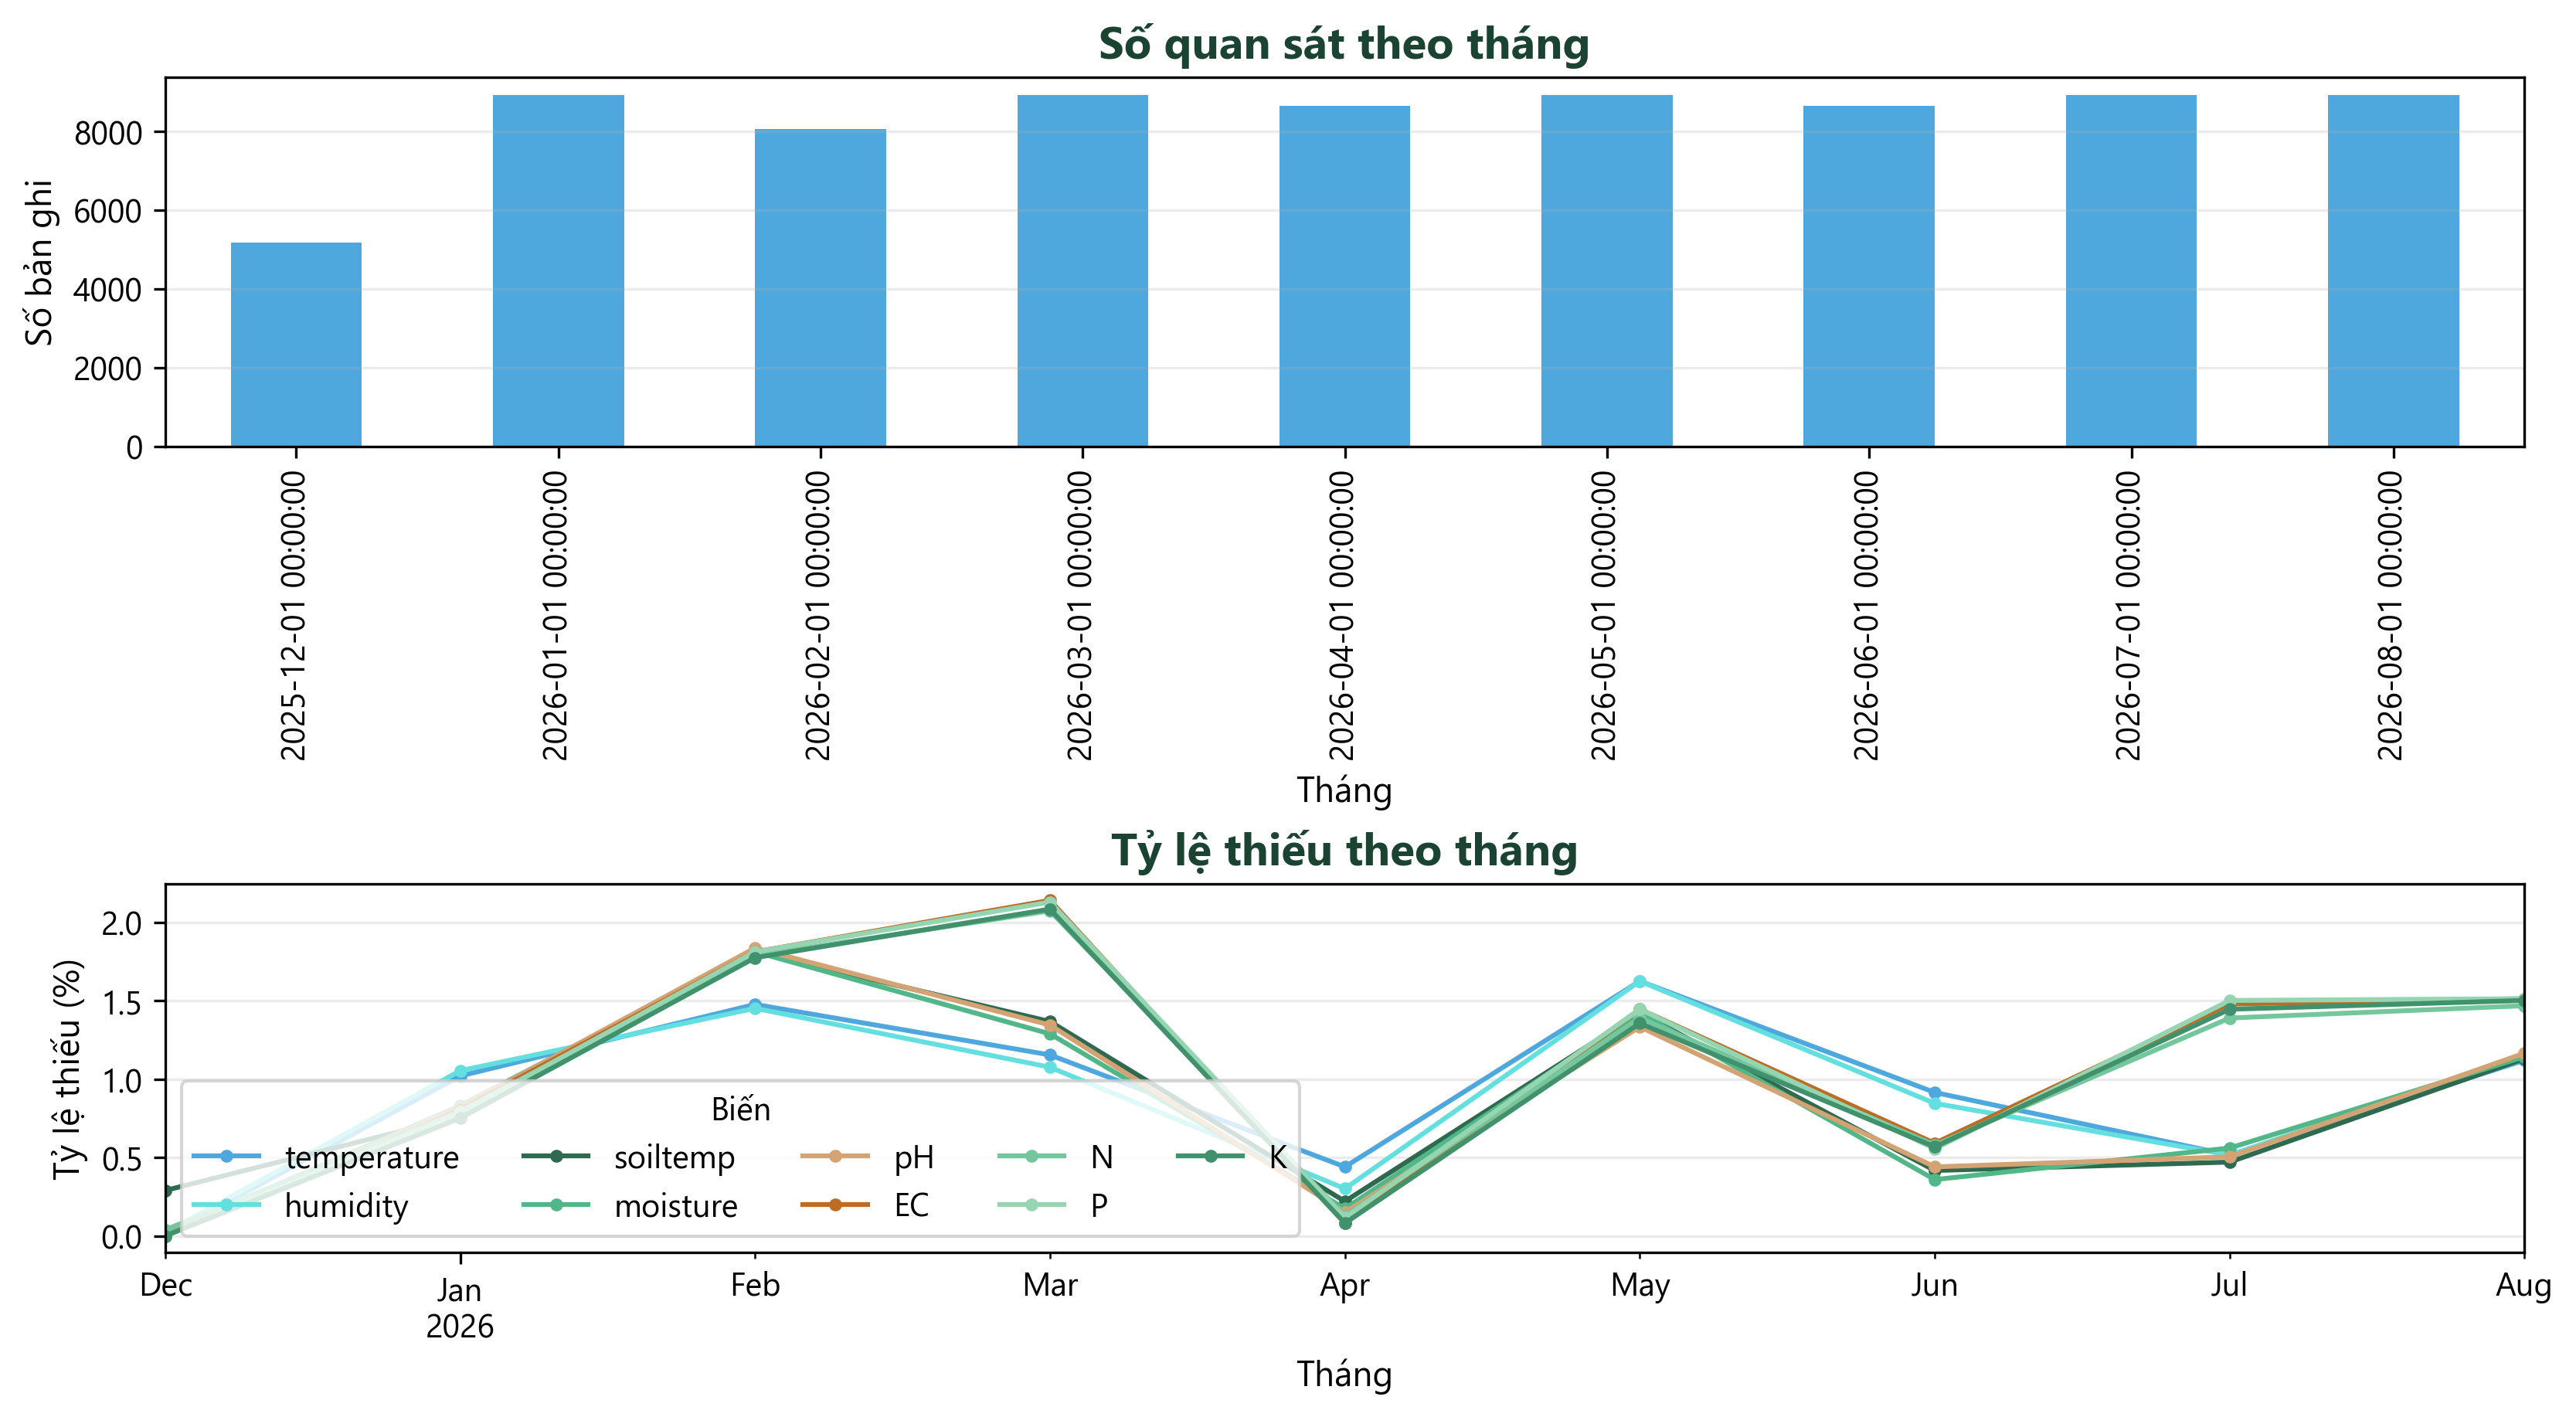

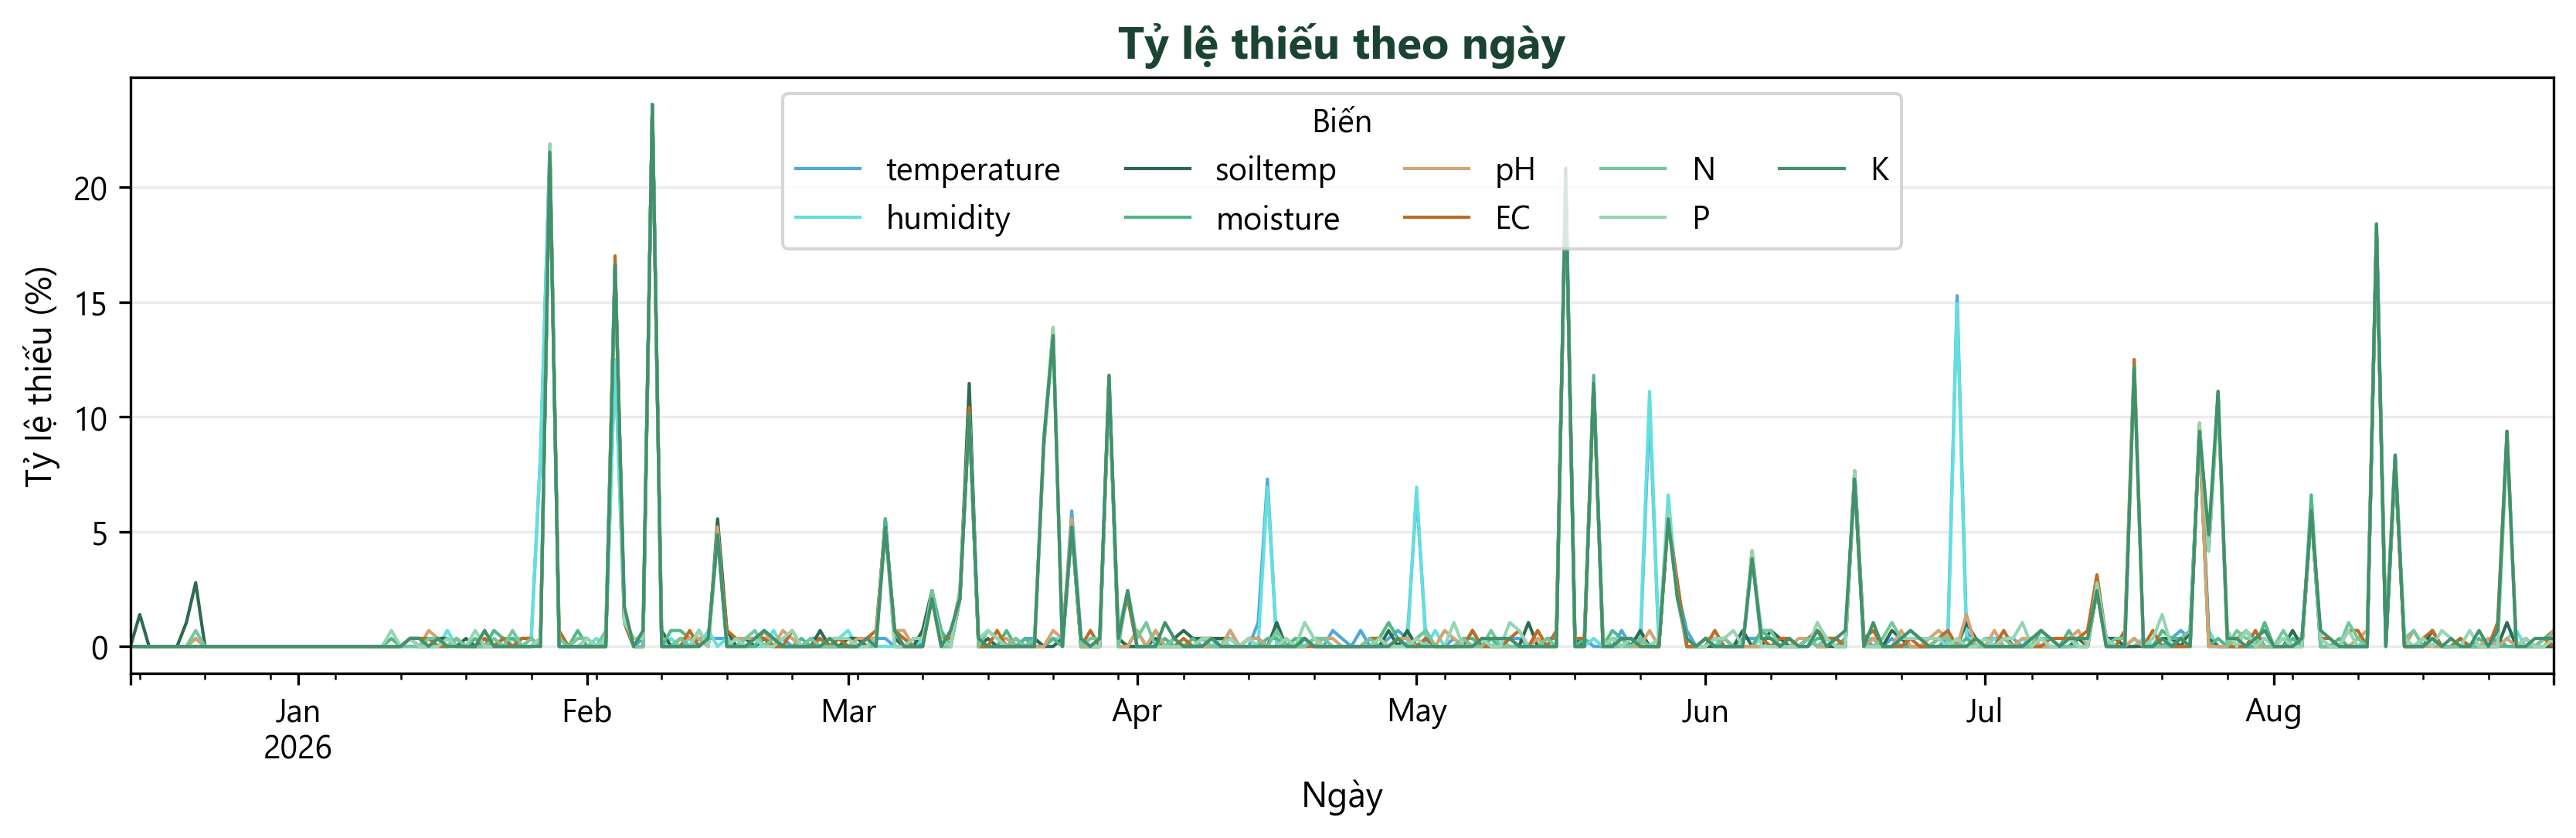

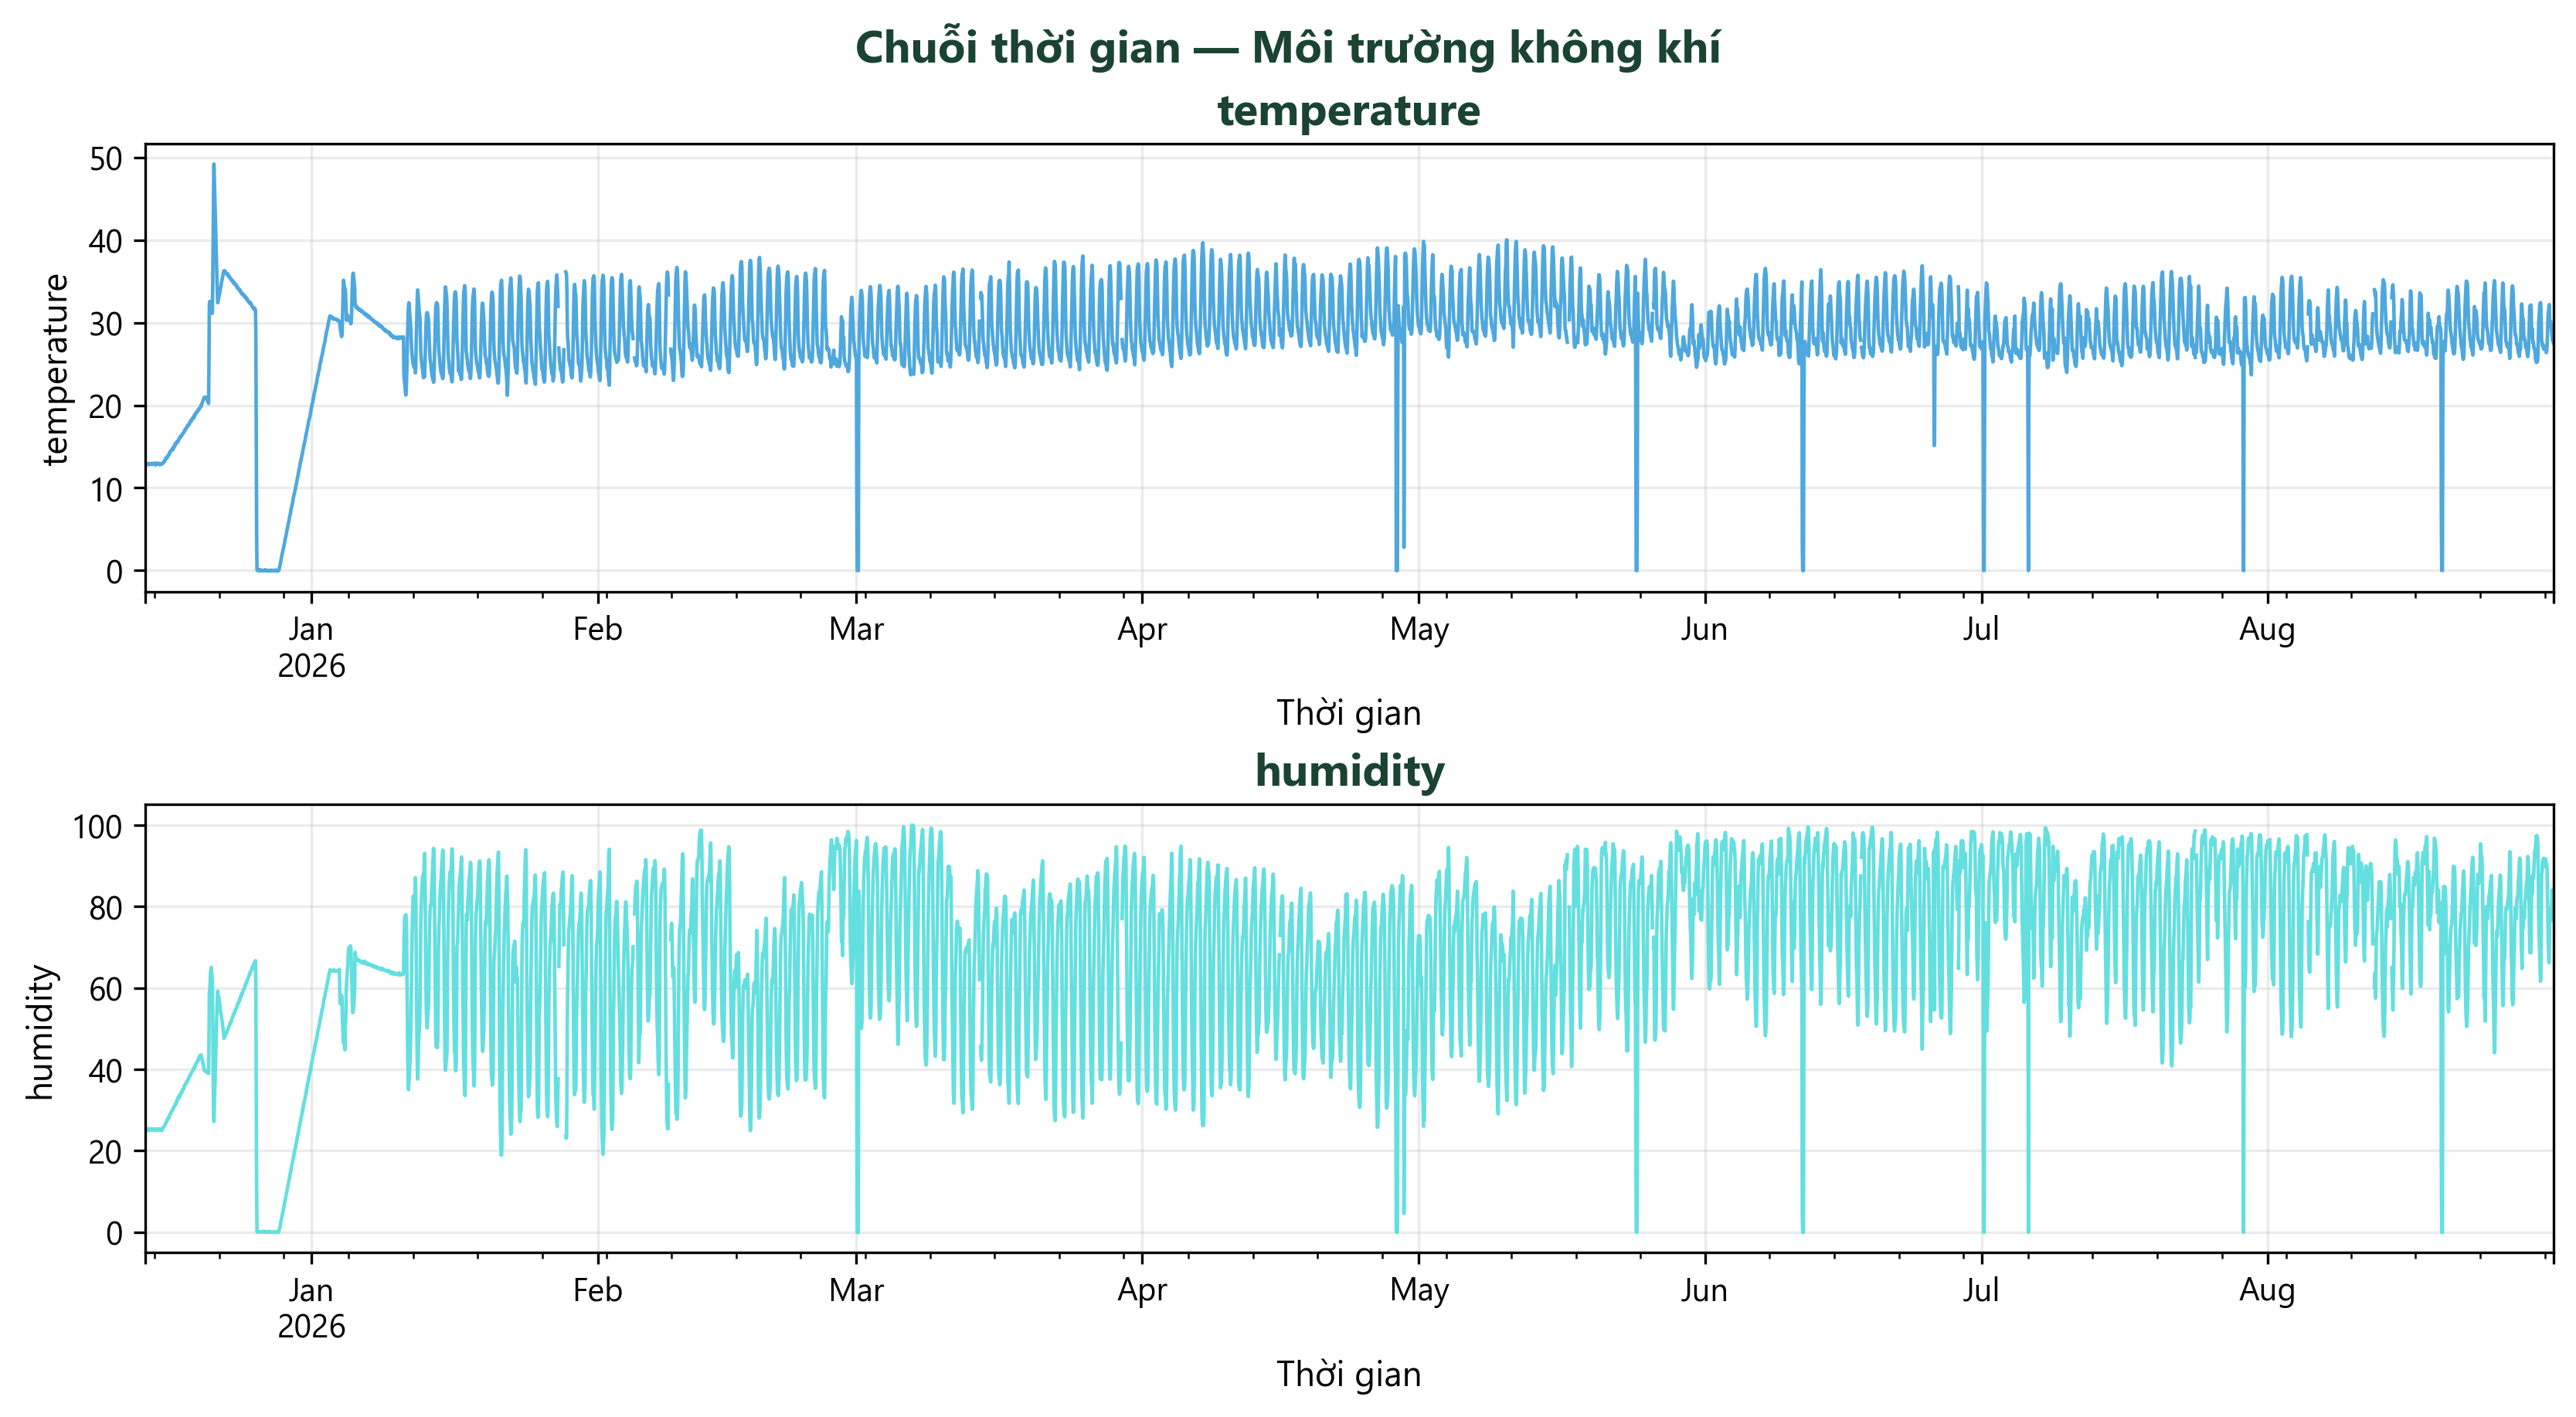

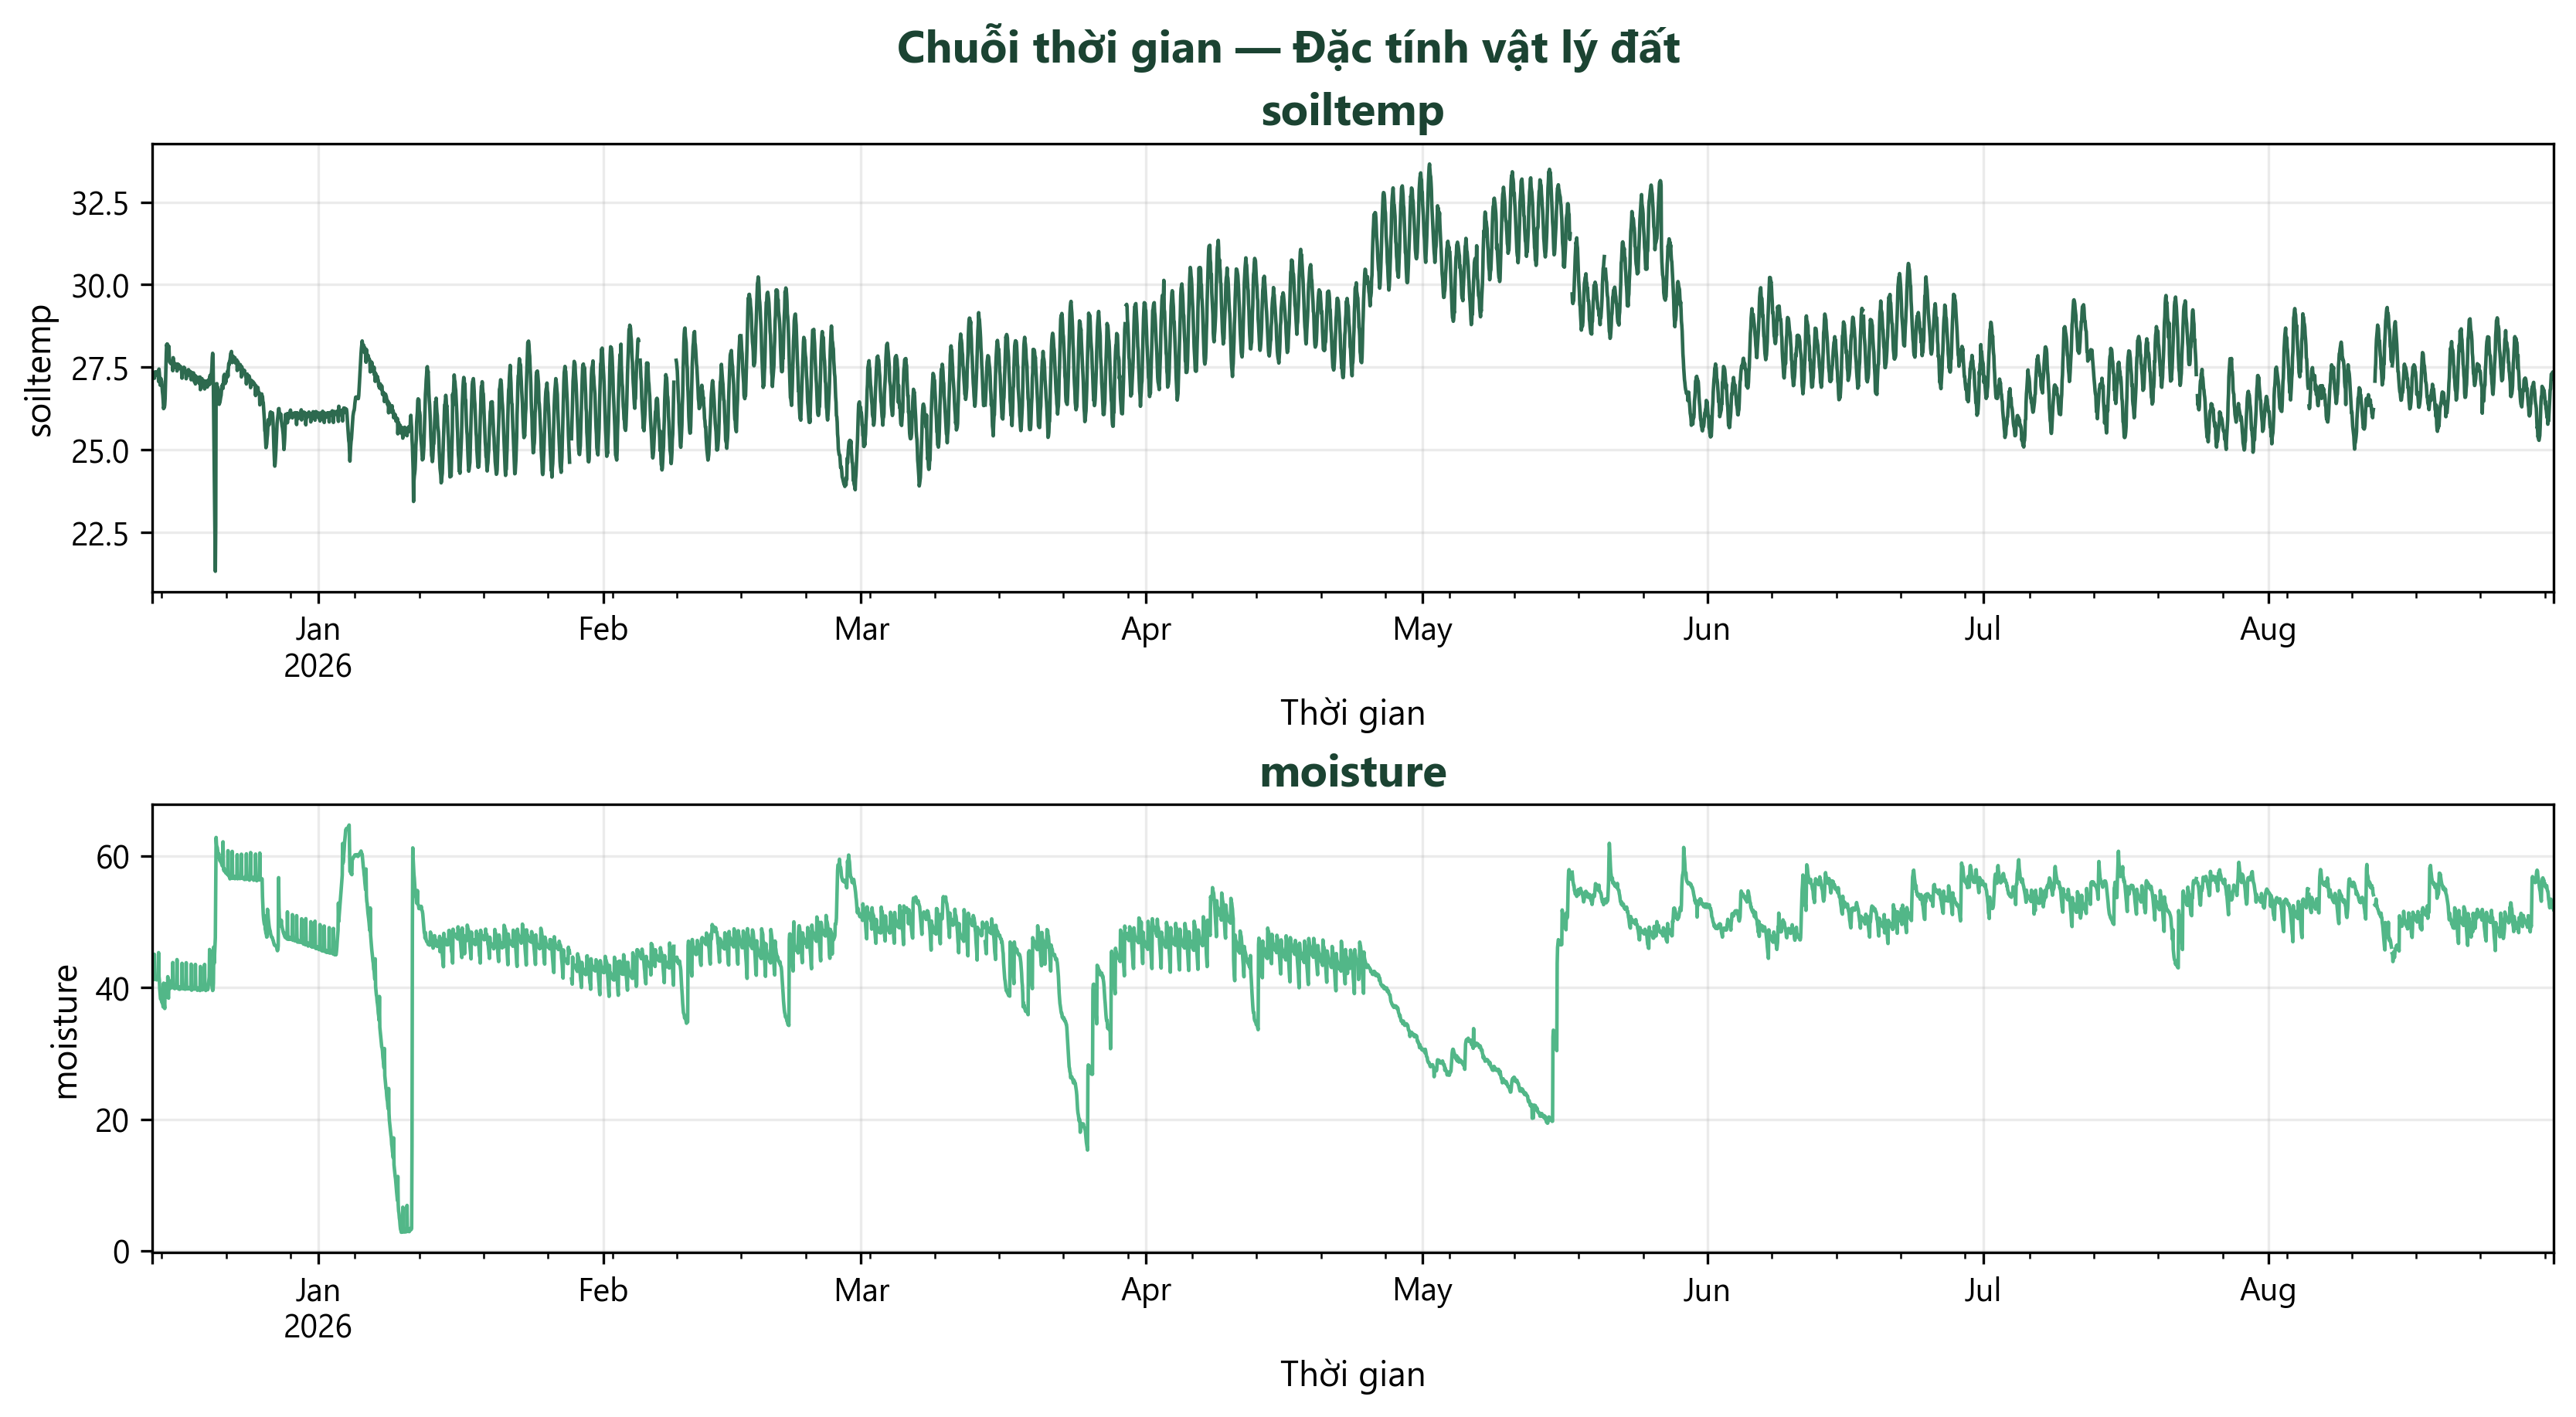

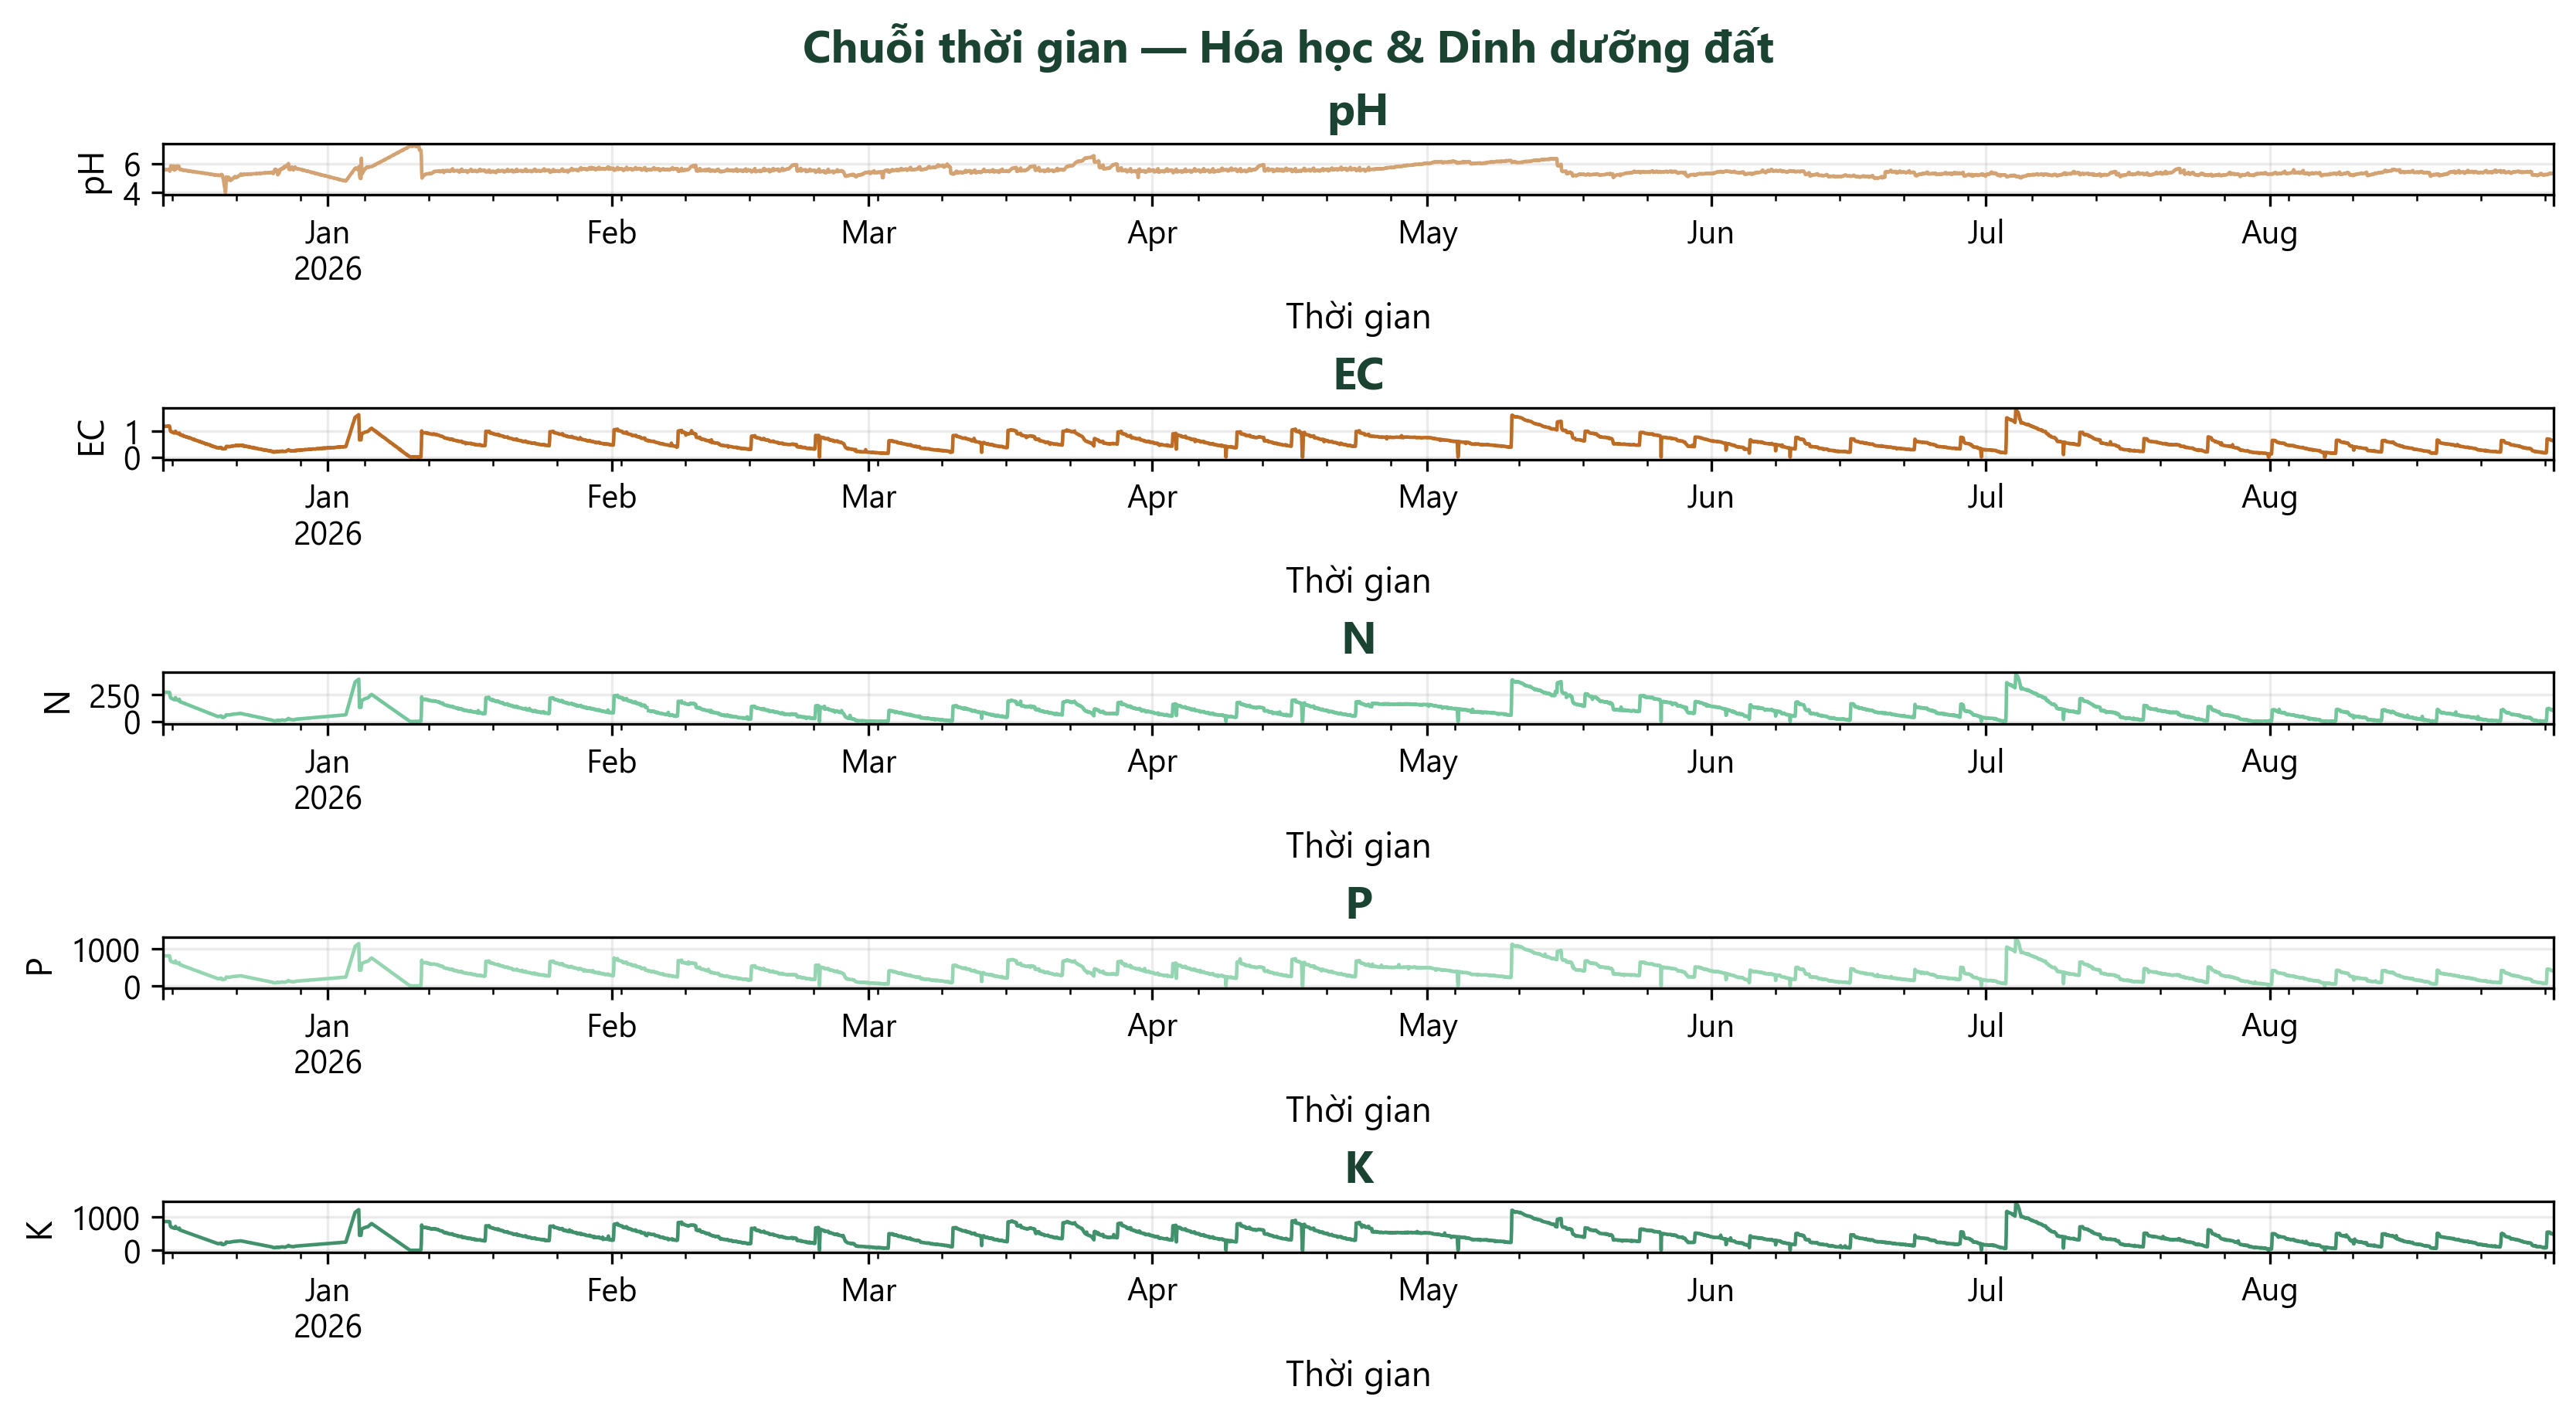

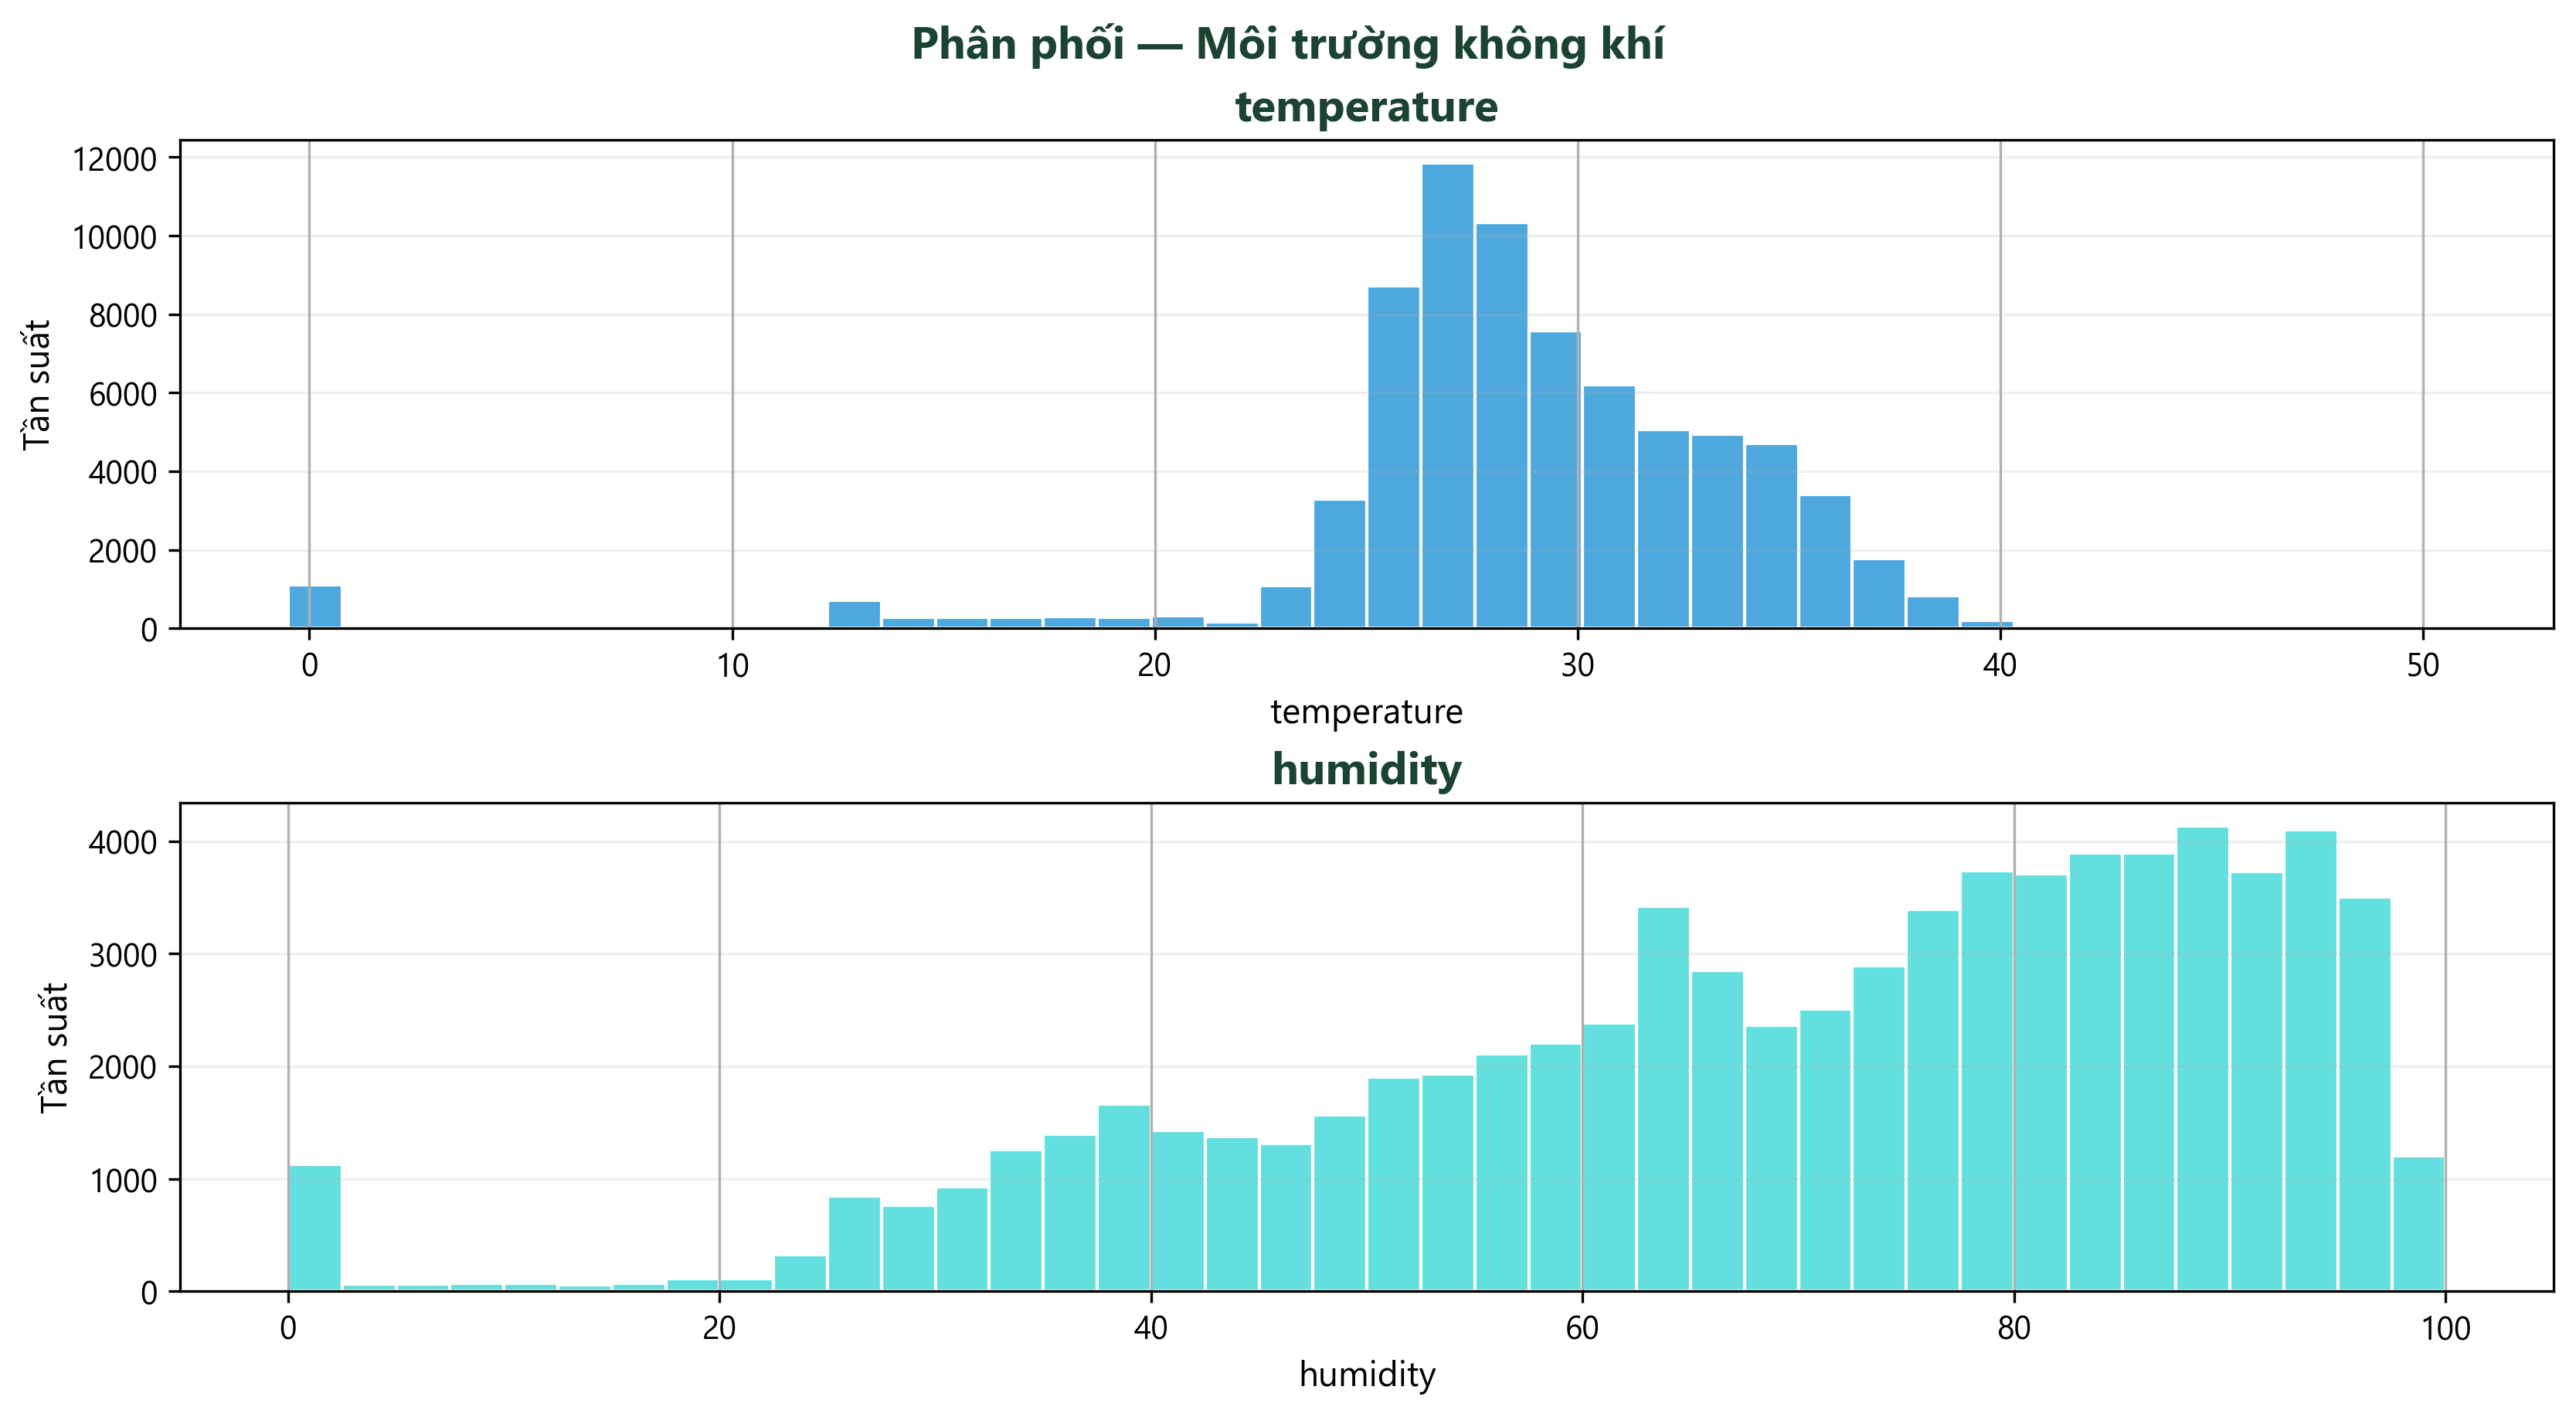

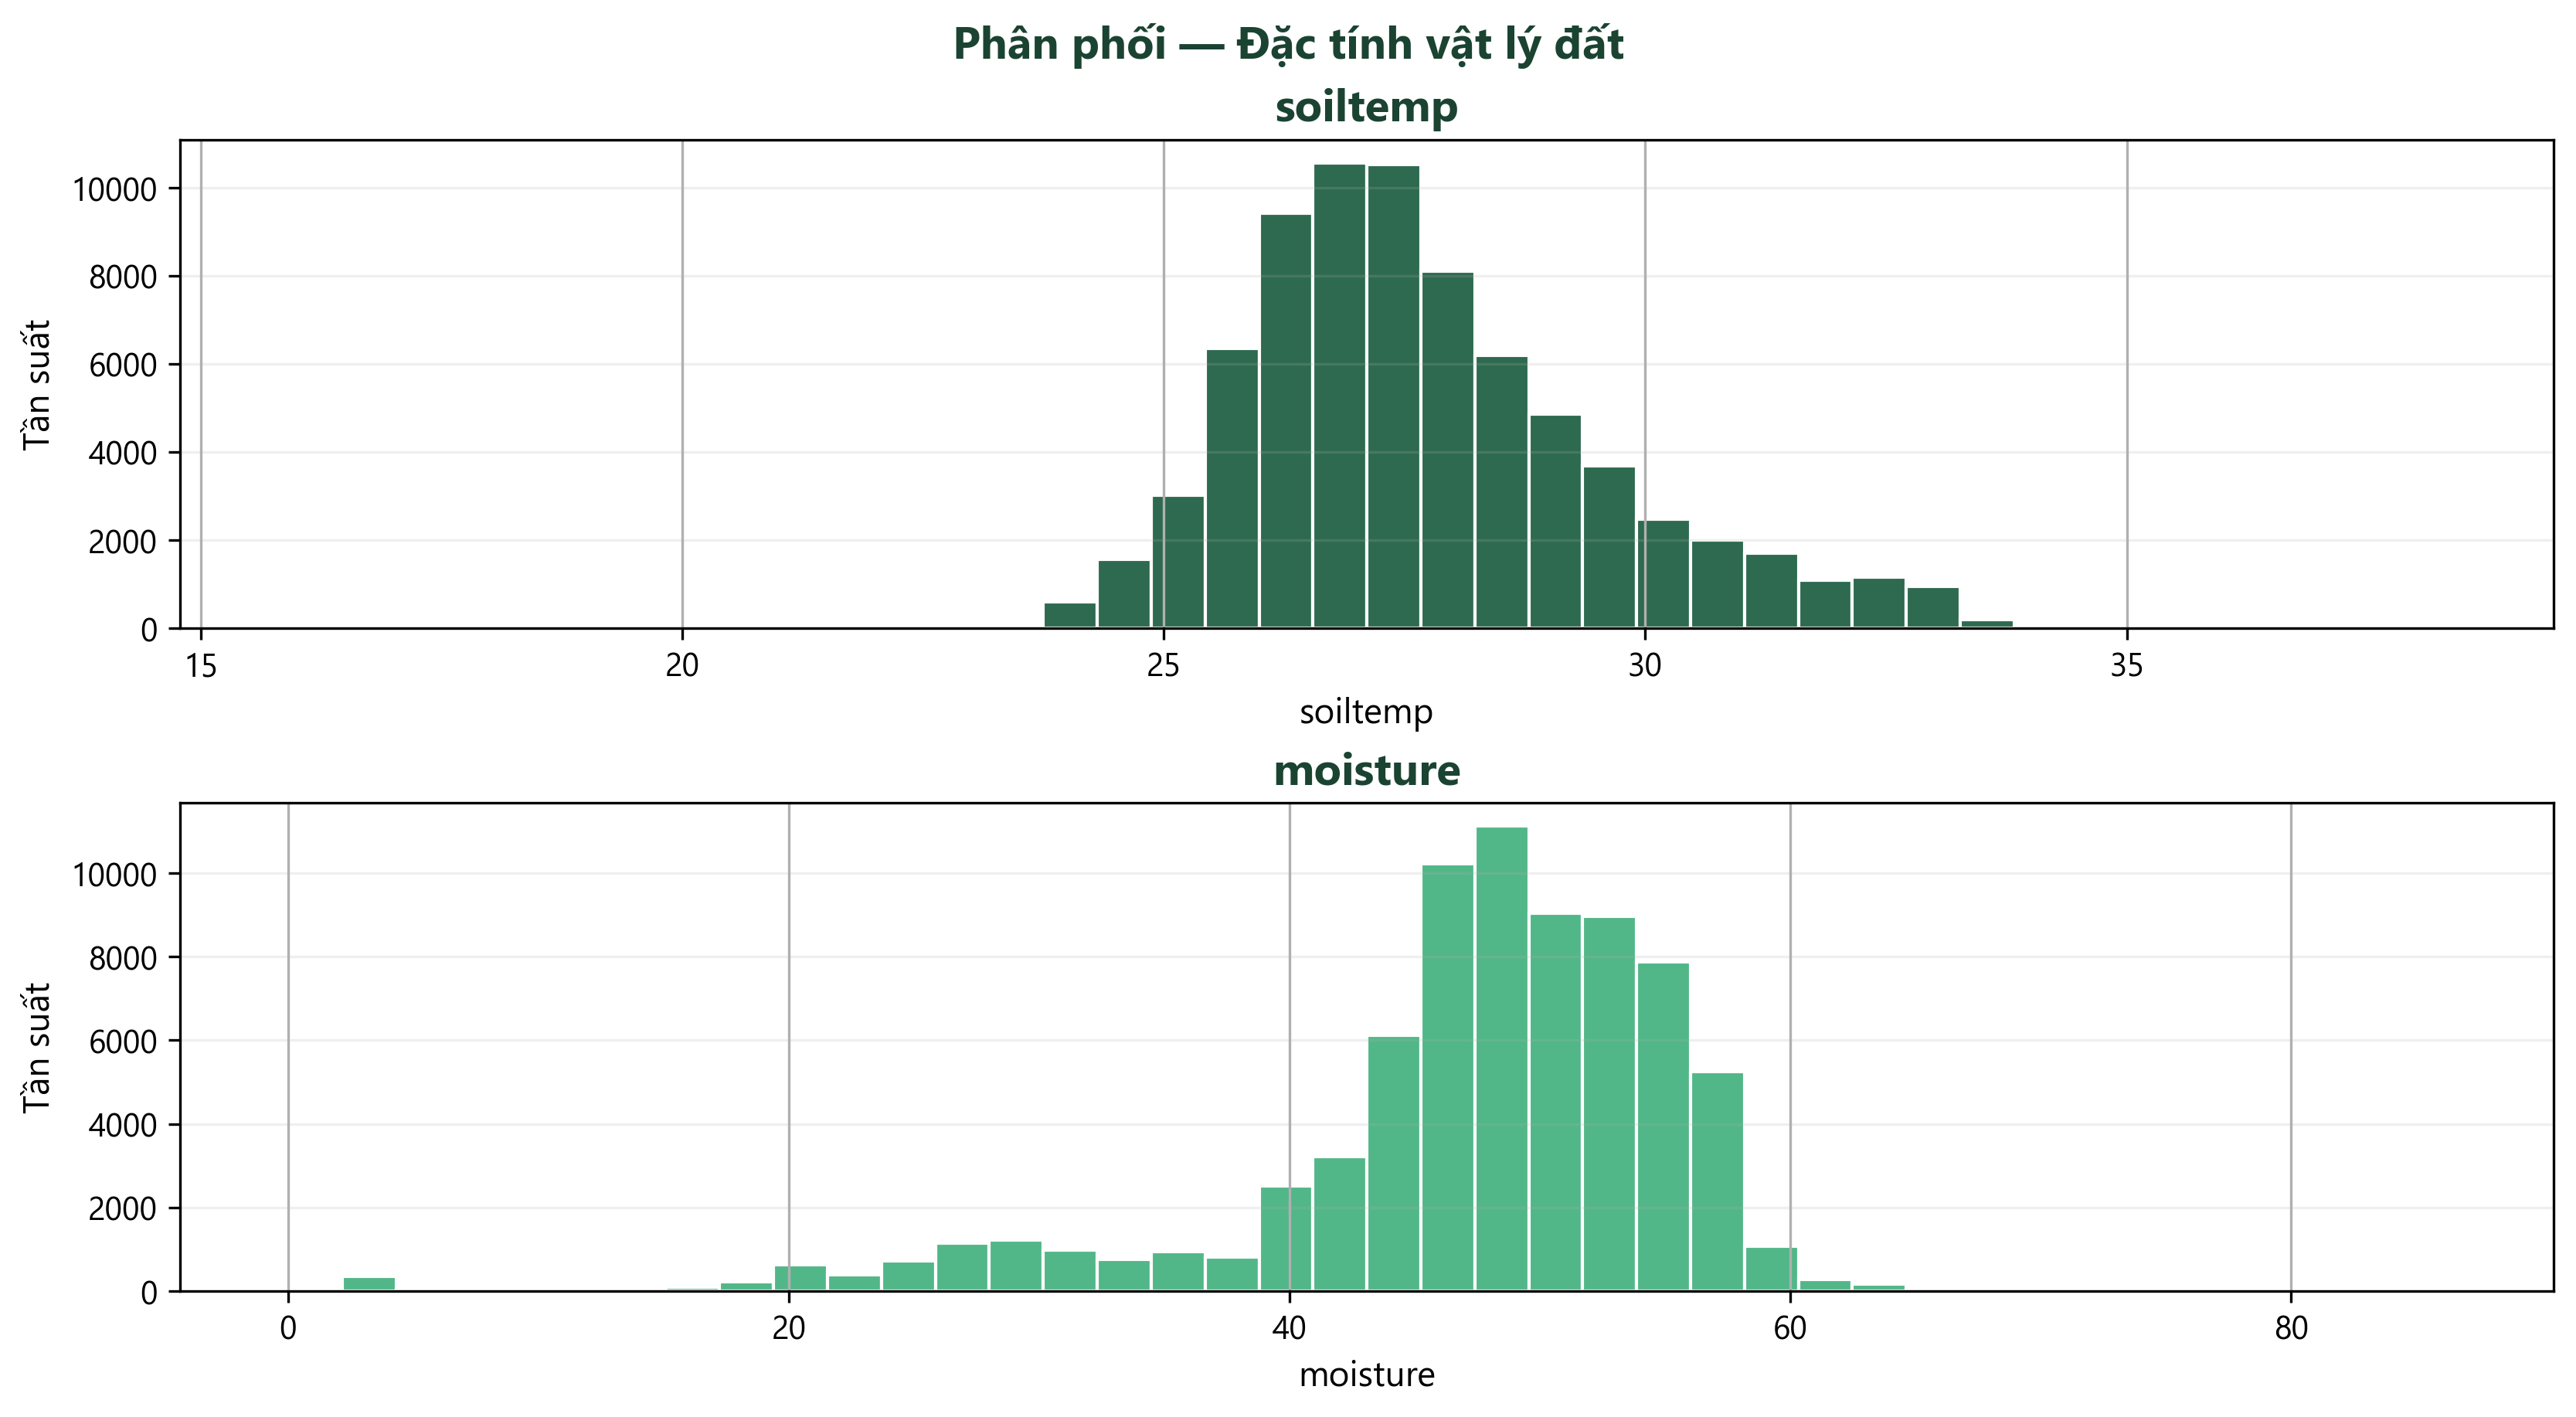

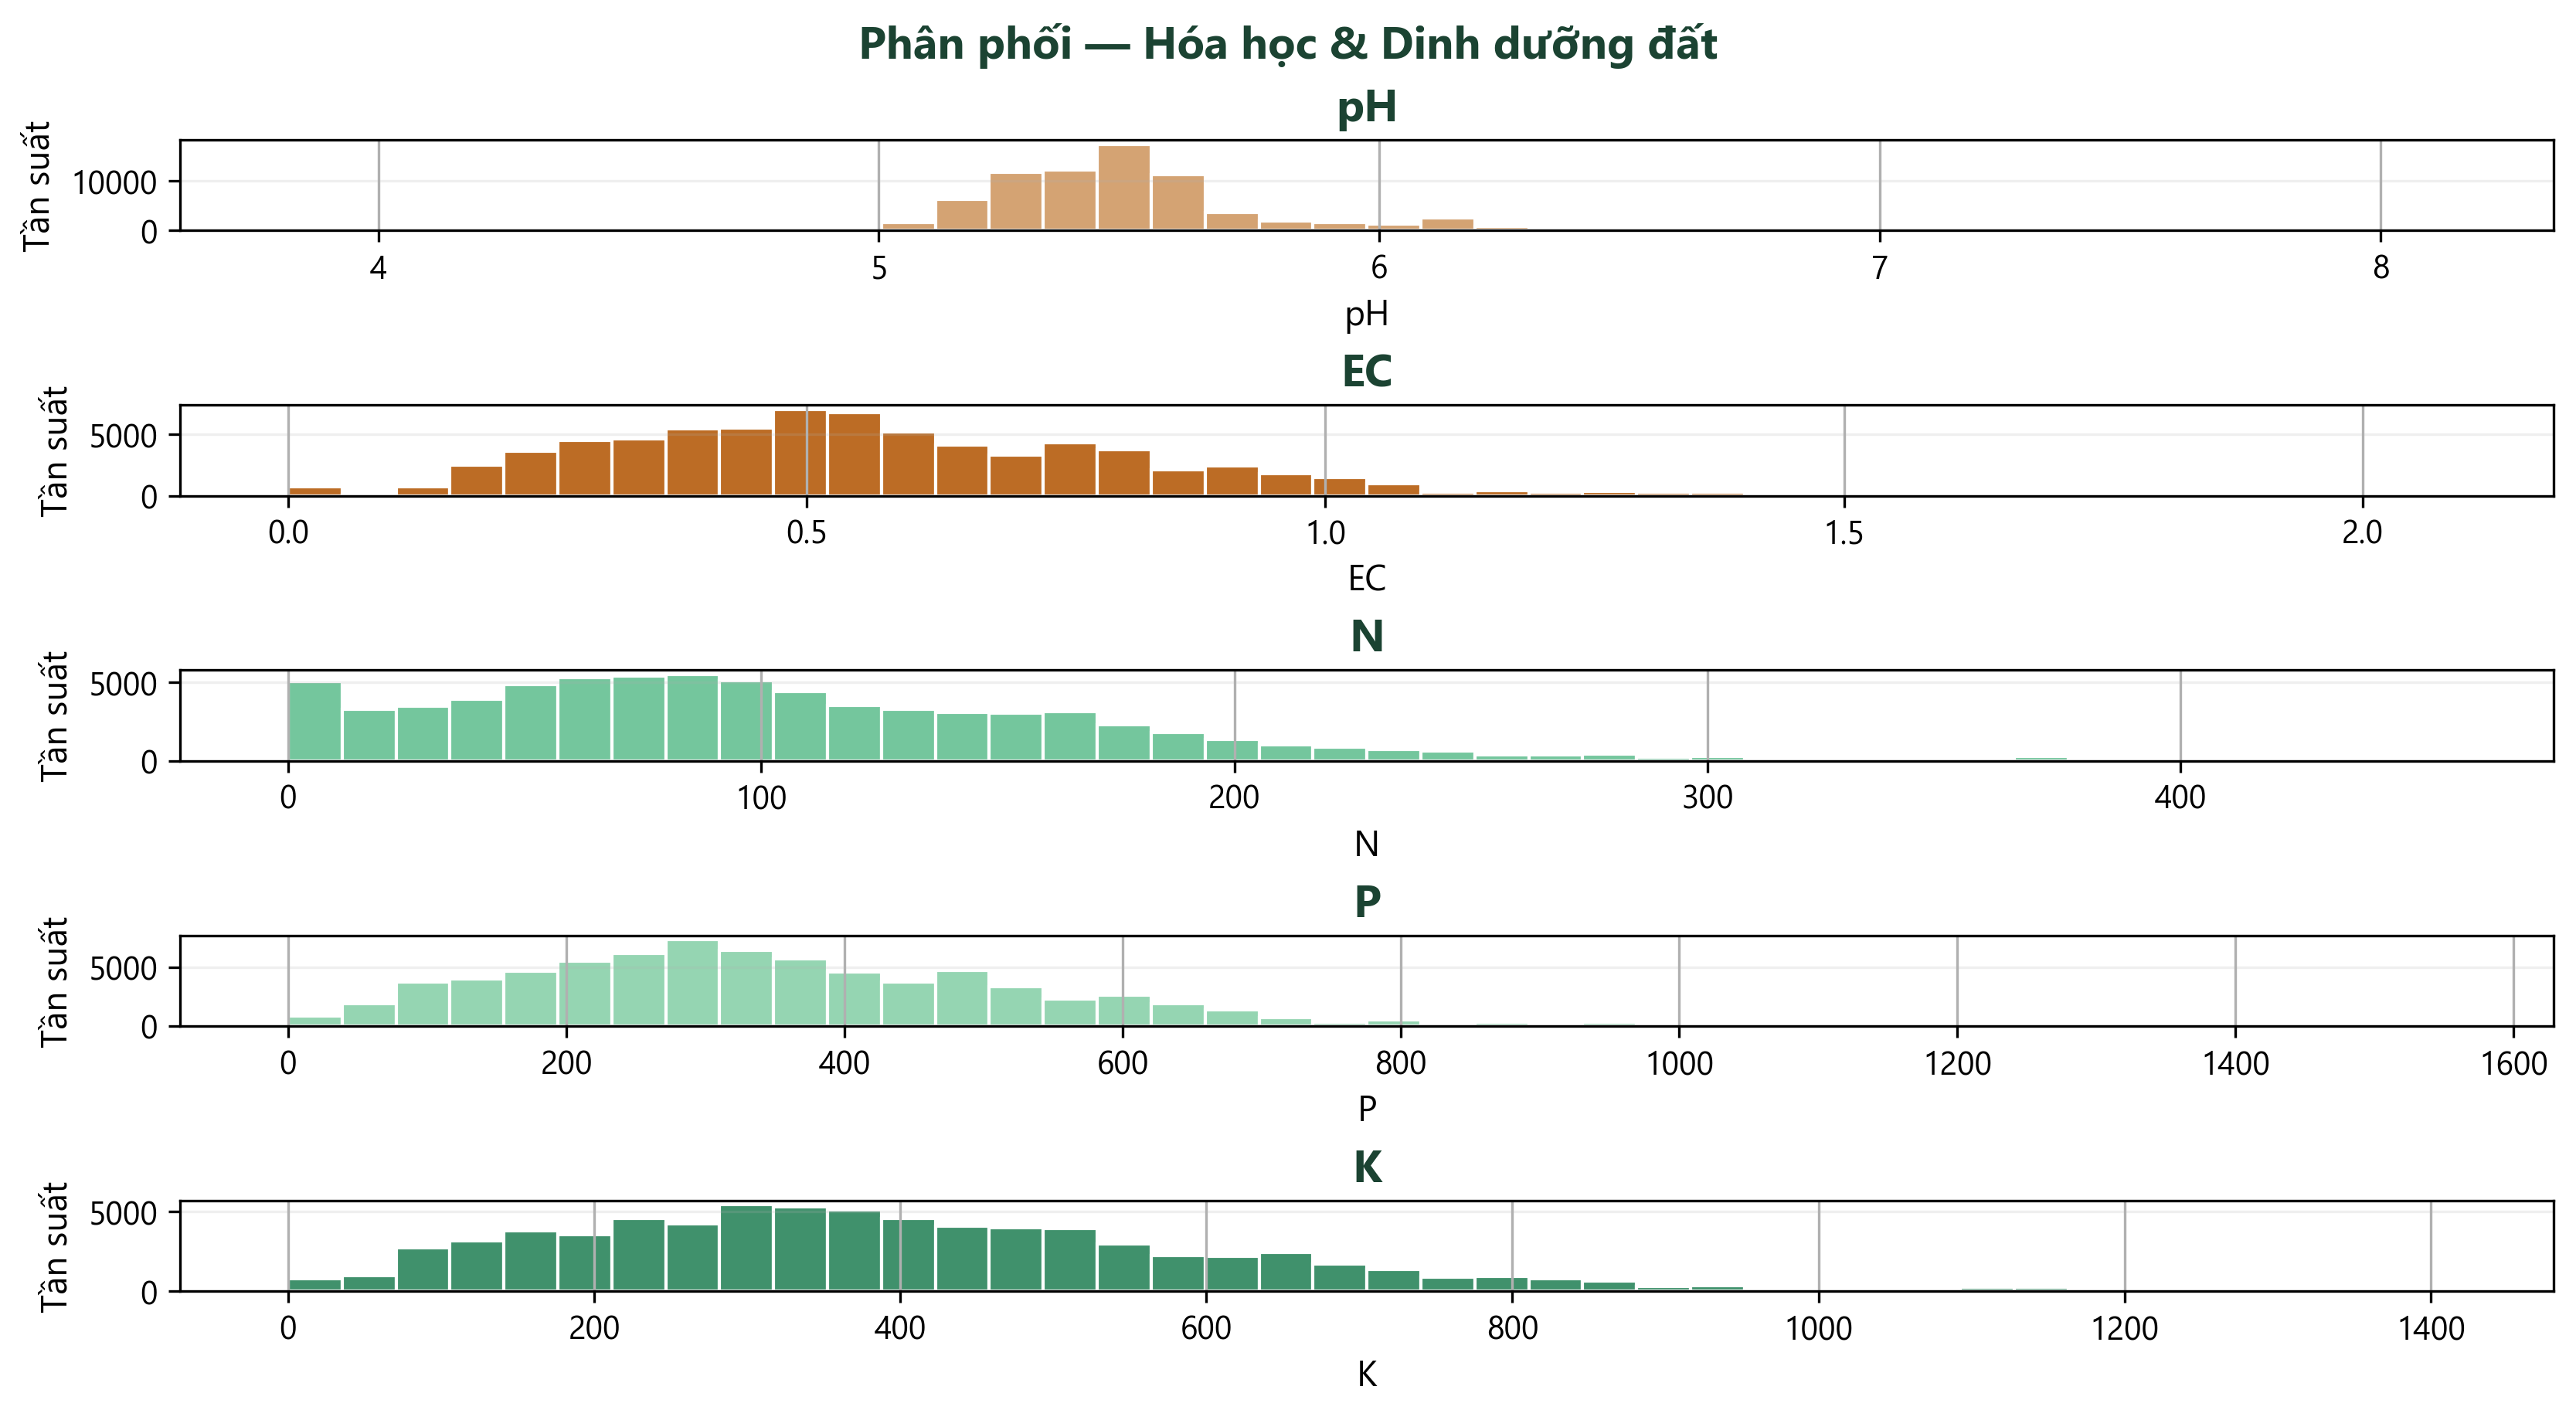

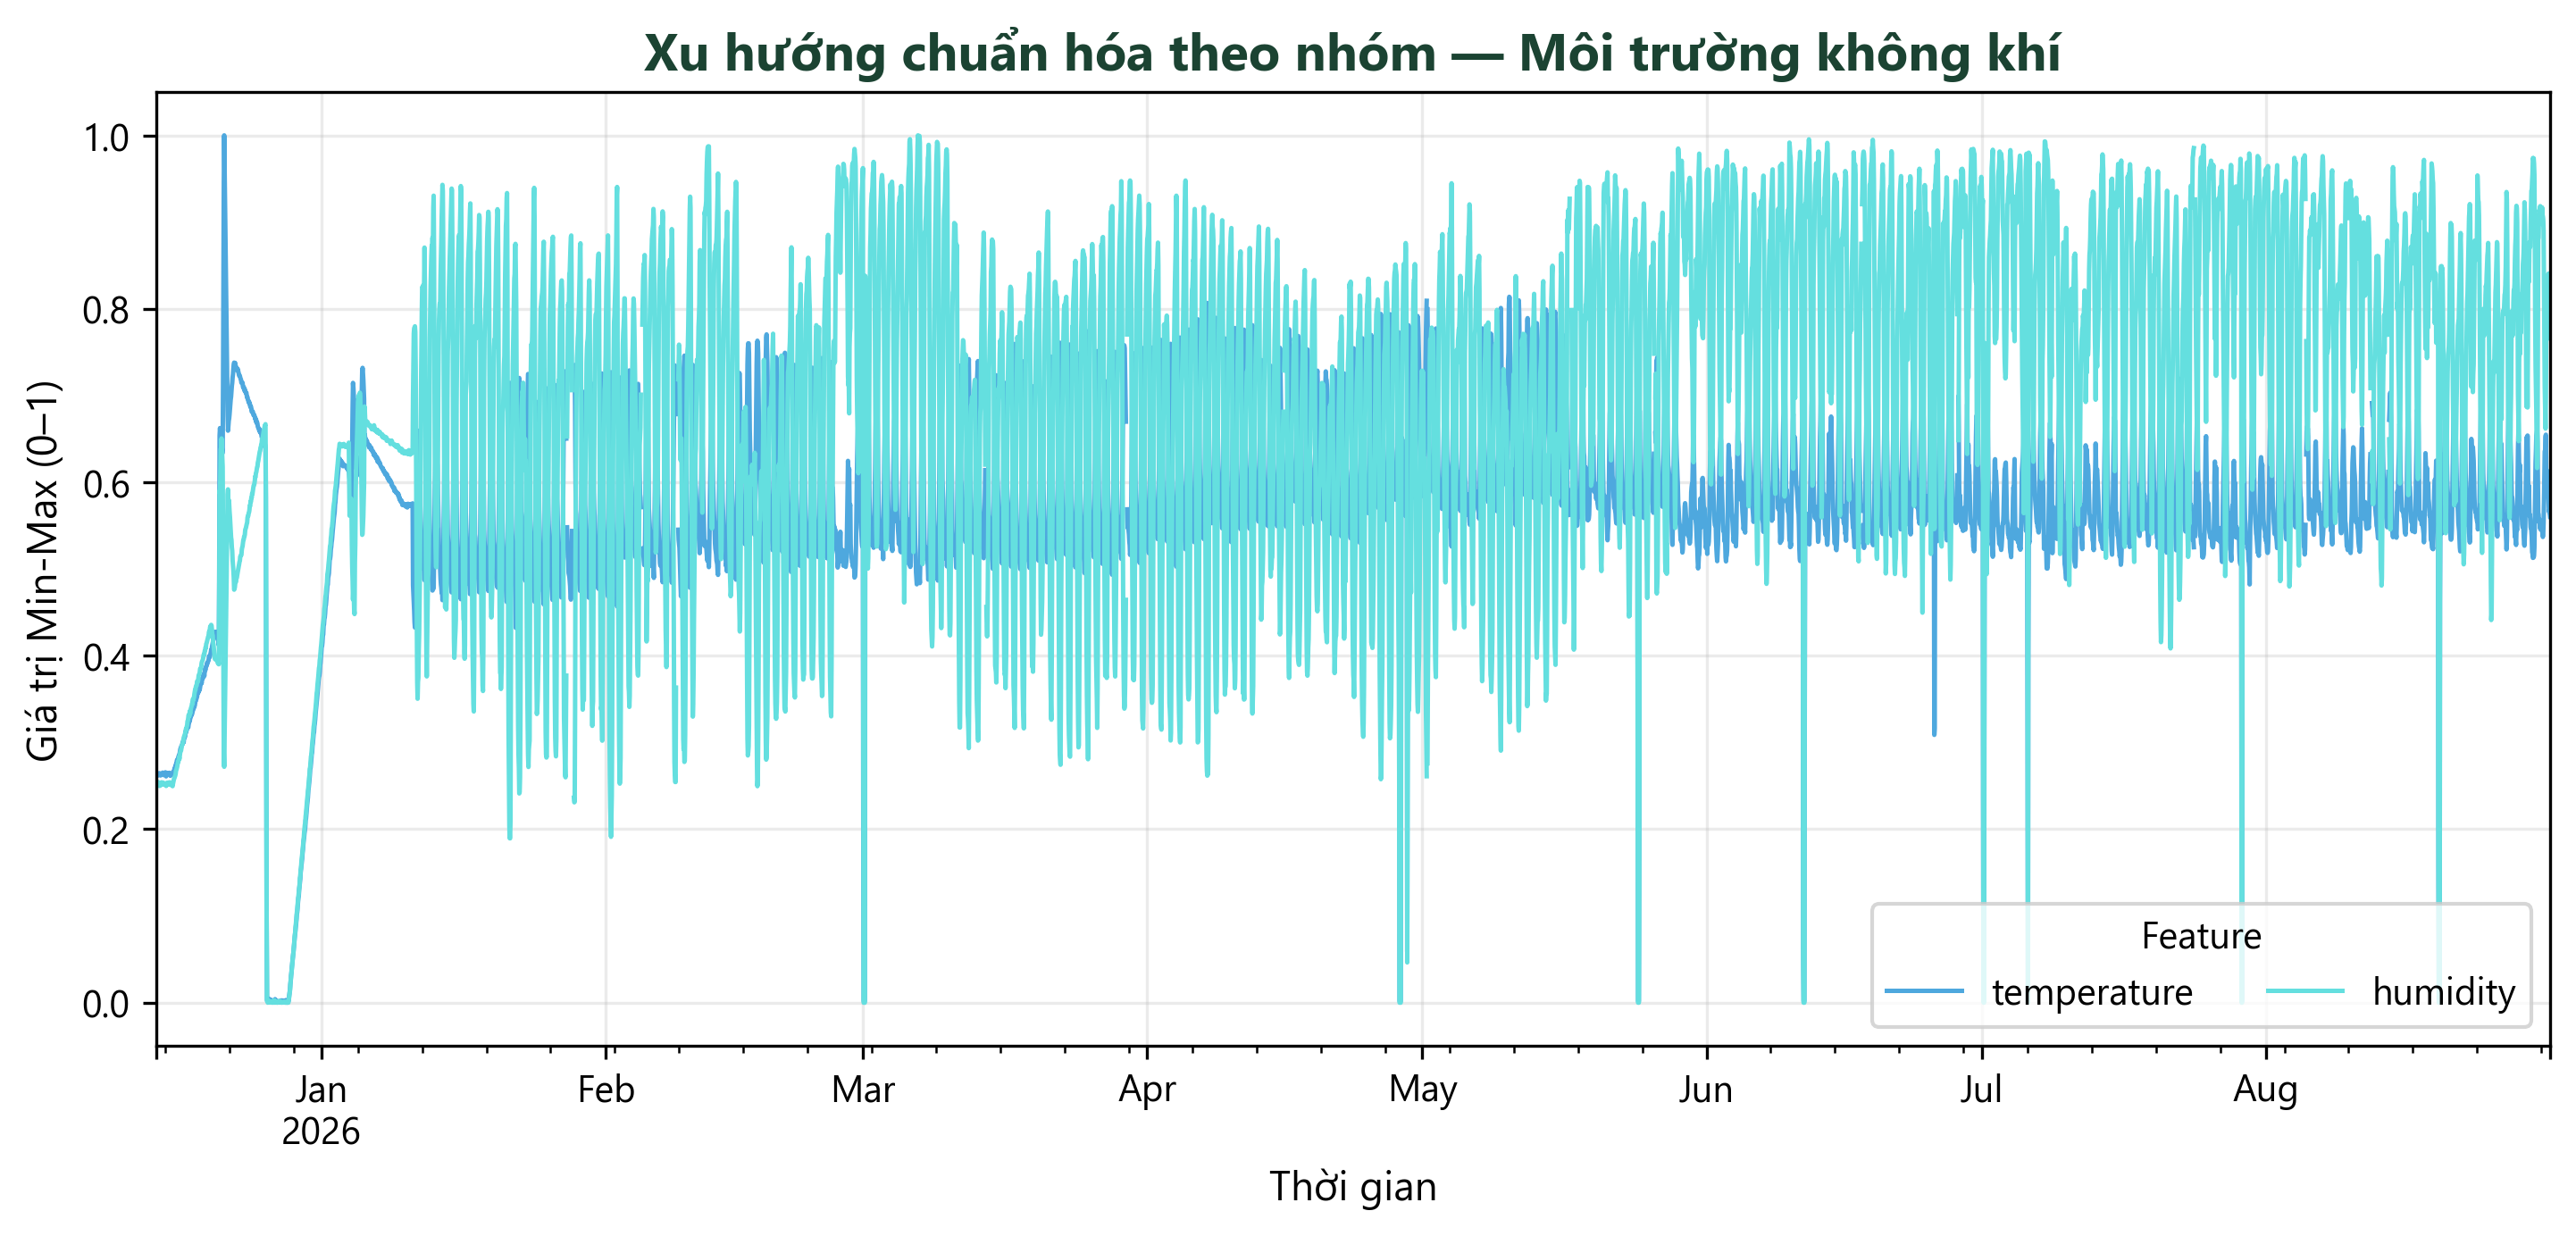

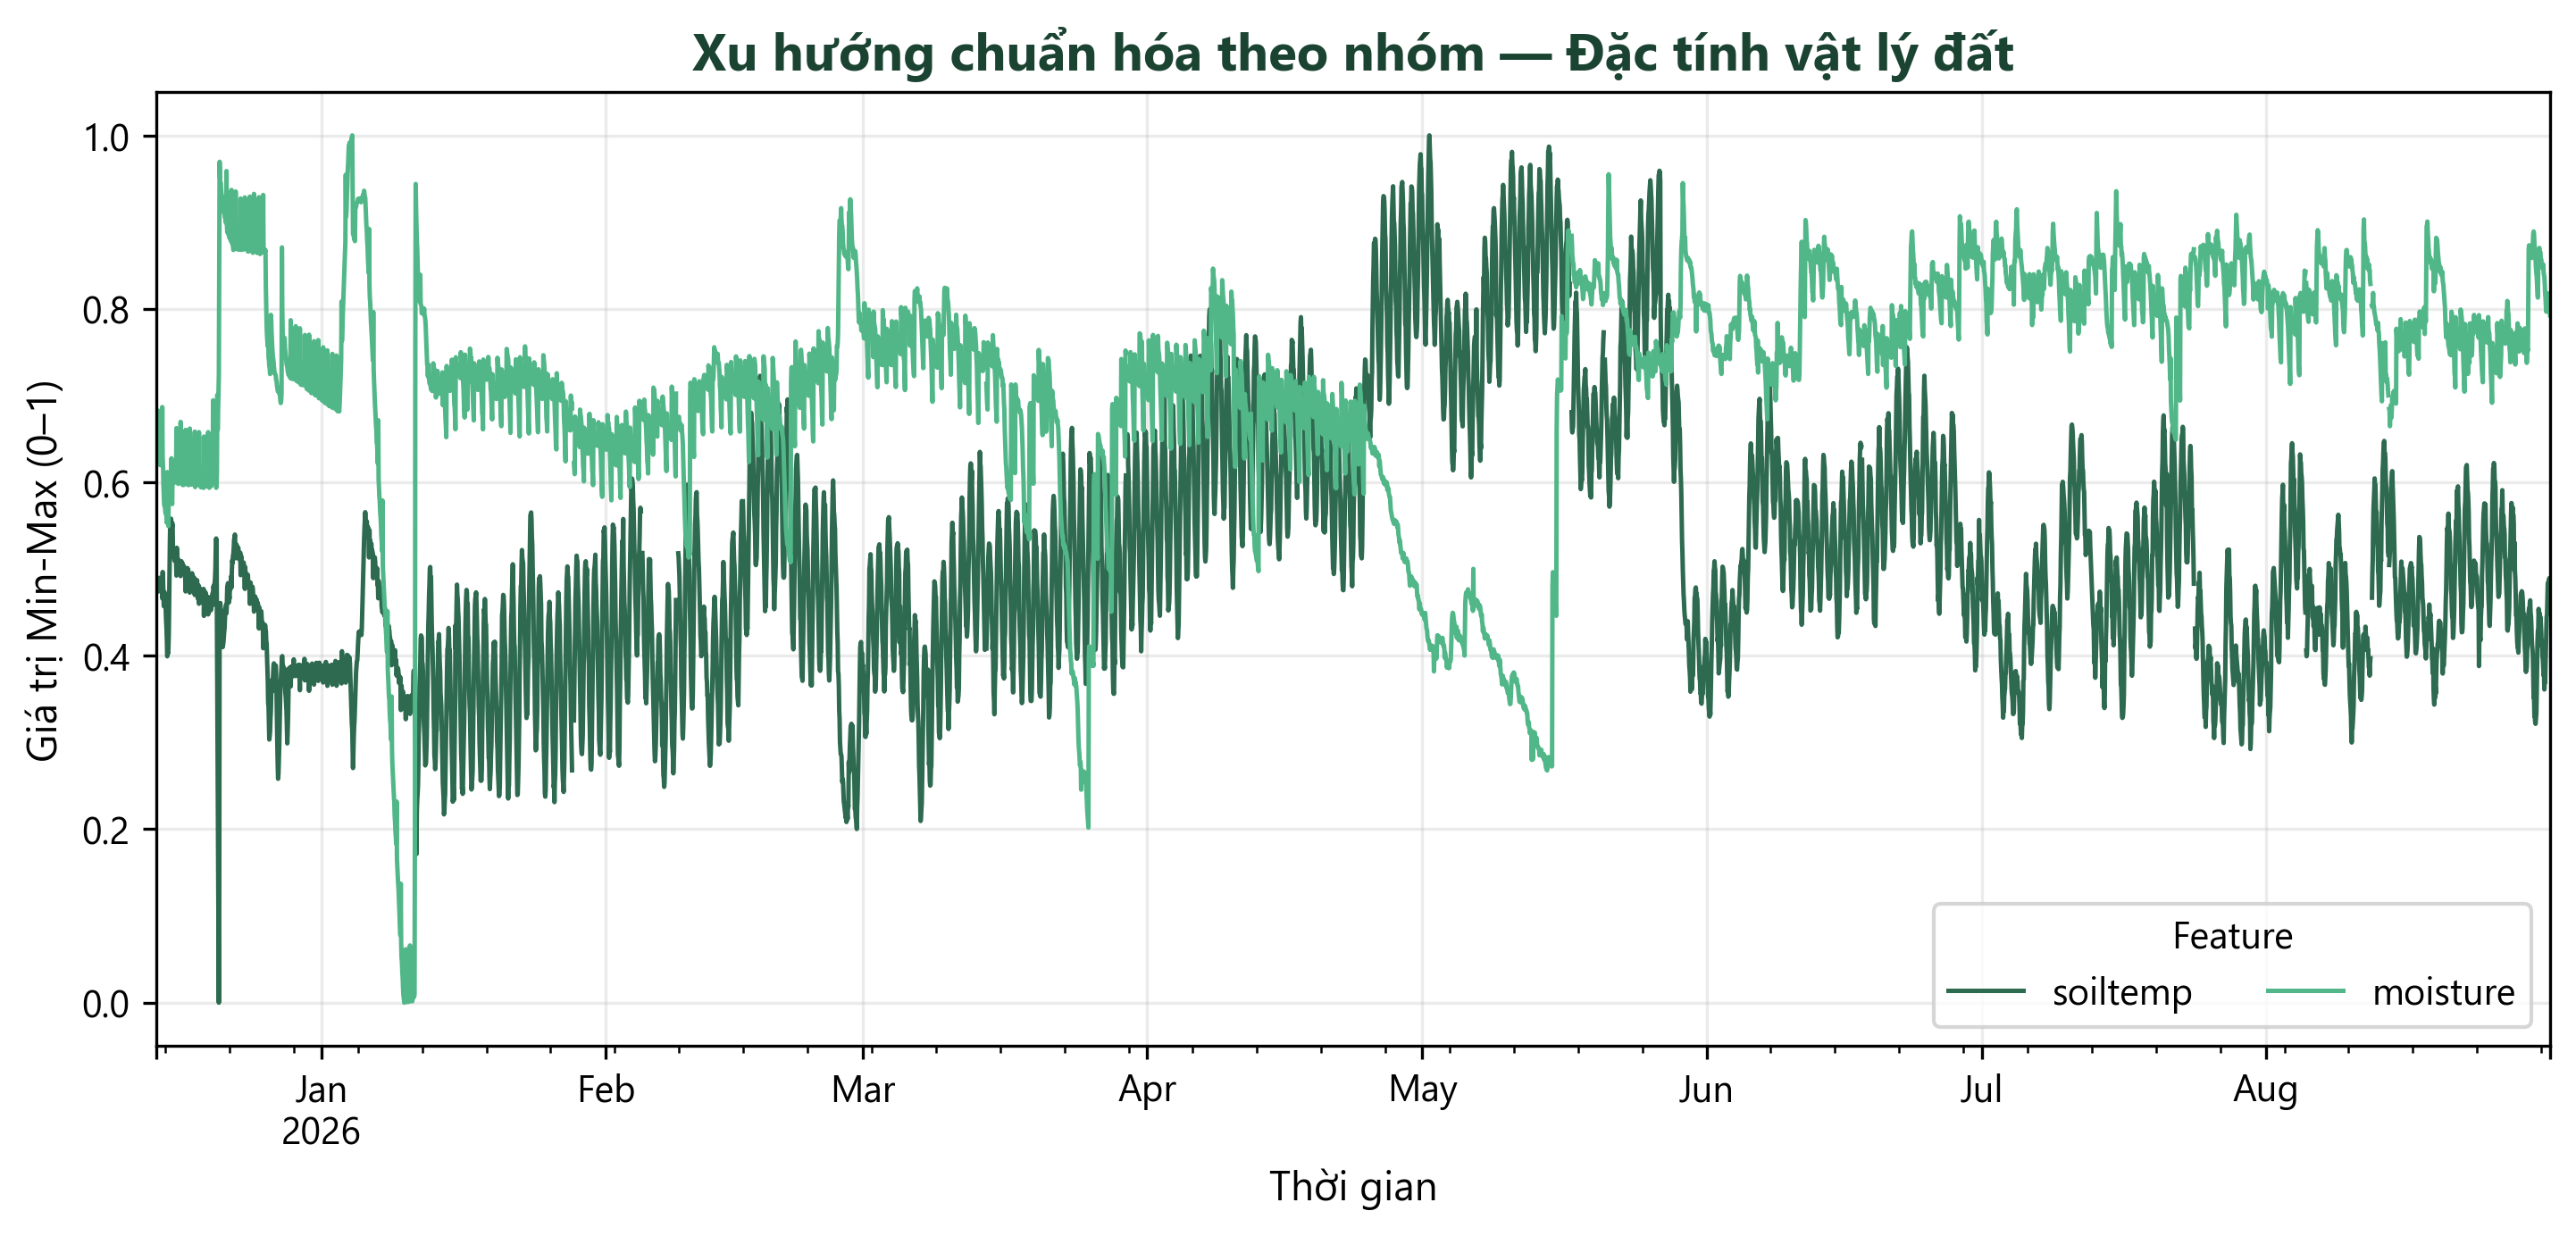

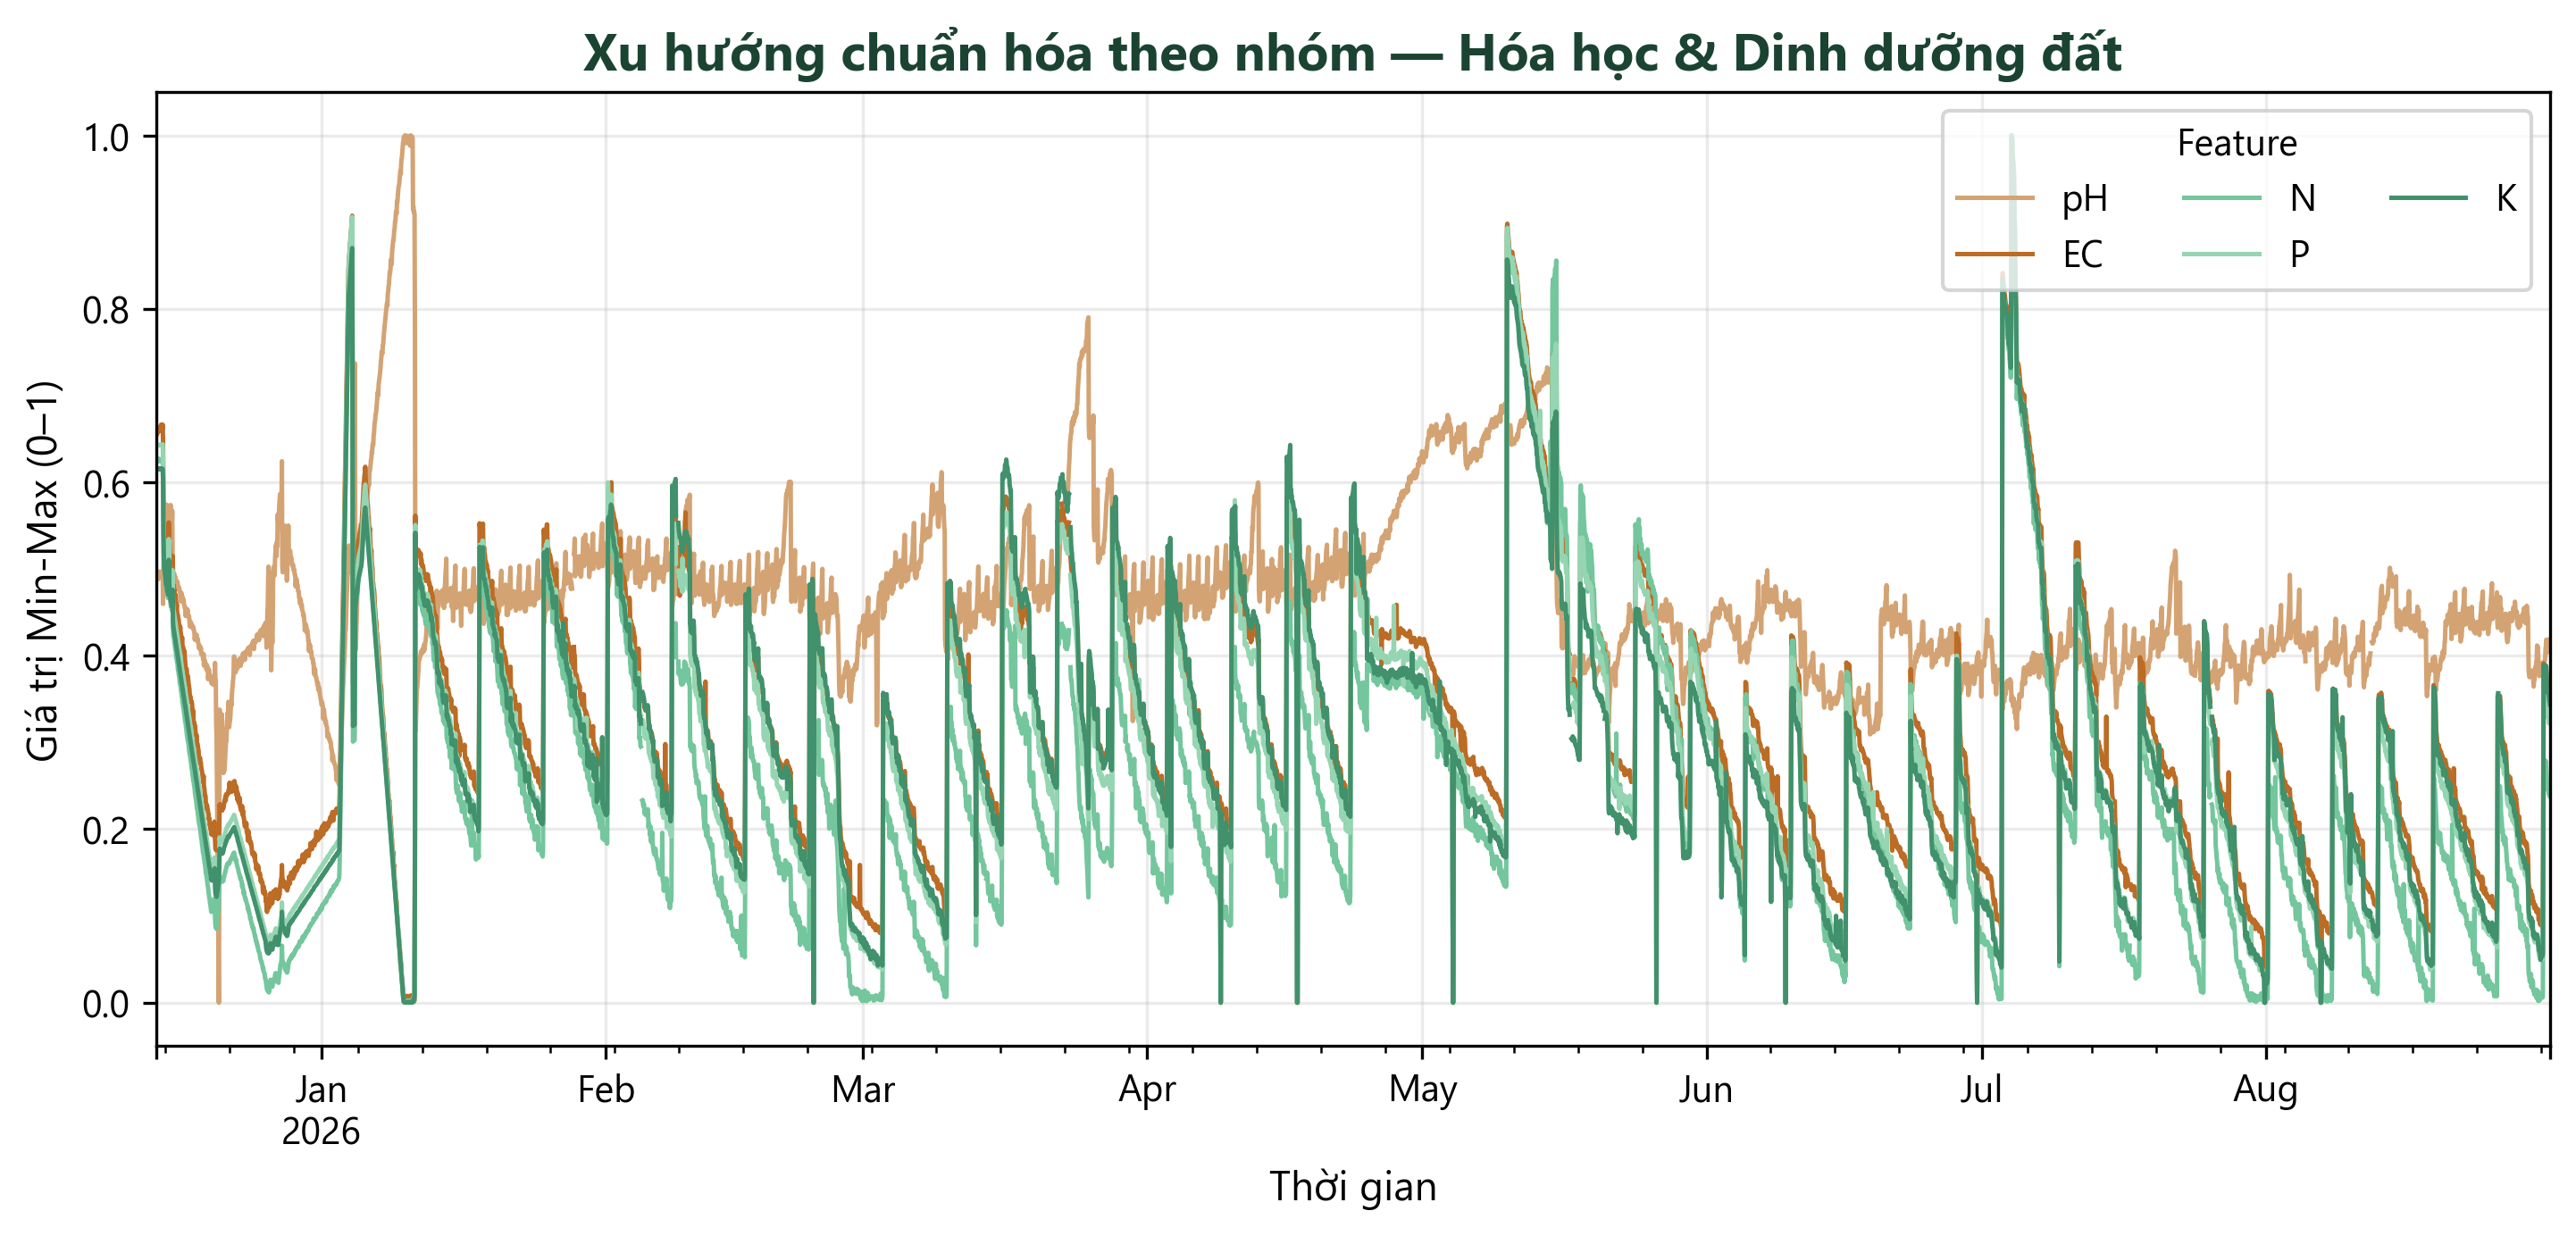

In [3]:
quality = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "count": df.count(),
    "missing": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(dropna=True),
    "mean": df.mean(numeric_only=True),
    "std": df.std(numeric_only=True),
    "min": df.min(numeric_only=True),
    "p25": df.quantile(0.25, numeric_only=True),
    "median": df.median(numeric_only=True),
    "p75": df.quantile(0.75, numeric_only=True),
    "max": df.max(numeric_only=True),
}).sort_values("missing_pct", ascending=False)
display(quality)

monthly_rows = df.resample("MS").size().rename("observations")
monthly_missing = df.isna().resample("MS").mean().mul(100)
fig, axes = plt.subplots(2, 1, figsize=(11, 6), dpi=300, constrained_layout=True)
monthly_rows.plot(kind="bar", ax=axes[0], color="#4EA8DE")
axes[0].set_title("Số quan sát theo tháng")
axes[0].set_ylabel("Số bản ghi")
axes[0].set_xlabel("Tháng")
monthly_missing.plot(ax=axes[1], marker=".", color=[SENSOR_COLORS.get(c, "#777777") for c in monthly_missing.columns])
axes[1].set_title("Tỷ lệ thiếu theo tháng")
axes[1].set_ylabel("Tỷ lệ thiếu (%)")
axes[1].set_xlabel("Tháng")
axes[1].legend(title="Biến", ncol=5)
for ax in axes:
    ax.grid(axis="y", alpha=0.25)
plt.show()

fig, ax = plt.subplots(figsize=(11, 3.5), dpi=300, constrained_layout=True)
daily_missing = df.isna().astype(int).resample("D").mean().mul(100)
daily_missing.plot(ax=ax, color=[SENSOR_COLORS.get(c, "#777777") for c in daily_missing.columns], linewidth=1)
ax.set_title("Tỷ lệ thiếu theo ngày")
ax.set_xlabel("Ngày")
ax.set_ylabel("Tỷ lệ thiếu (%)")
ax.legend(title="Biến", ncol=5)
ax.grid(axis="y", alpha=0.25)
plt.show()

# Gom trung bình theo giờ để chuỗi dài 5 phút dễ đọc trên slide.
sensor_plot_df = df.resample("1h").mean()
for group_name, group in SENSOR_GROUPS.items():
    columns = [column for column in group["columns"] if column in df.columns]
    if not columns:
        continue
    ncols = min(1, len(columns))
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 6), dpi=300, squeeze=False, constrained_layout=True)
    for index, (ax, column) in enumerate(zip(axes.flat, columns)):
        color = SENSOR_COLORS[column]
        sensor_plot_df[column].plot(ax=ax, color=color, linewidth=1.1)
        ax.set_title(column)
        ax.set_xlabel("Thời gian")
        ax.set_ylabel(column)
        ax.grid(alpha=0.25)
    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(f"Chuỗi thời gian — {group_name}", fontsize=14, fontweight="bold", color=TITLE_COLOR)
    plt.show()

for group_name, group in SENSOR_GROUPS.items():
    columns = [column for column in group["columns"] if column in df.columns]
    if not columns:
        continue
    ncols = min(1, len(columns))
    nrows = int(np.ceil(len(columns) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(11, 6), dpi=300, squeeze=False, constrained_layout=True)
    for ax, column in zip(axes.flat, columns):
        df[column].dropna().hist(ax=ax, bins=40, color=SENSOR_COLORS[column], edgecolor="white")
        ax.set_title(column)
        ax.set_xlabel(column)
        ax.set_ylabel("Tần suất")
        ax.grid(axis="y", alpha=0.2)
    for ax in axes.flat[len(columns):]:
        ax.set_visible(False)
    fig.suptitle(f"Phân phối — {group_name}", fontsize=14, fontweight="bold", color=TITLE_COLOR)
    plt.show()

# Overlay all variables in each group in one chart. Min-max scaling gives a
# shared 0-1 axis without implying the sensor variables share physical units.
for group_name, group in SENSOR_GROUPS.items():
    columns = [column for column in group["columns"] if column in sensor_plot_df.columns]
    if not columns:
        continue
    group_data = sensor_plot_df[columns]
    minima = group_data.min()
    ranges = (group_data.max() - minima).replace(0, 1)
    normalized = (group_data - minima) / ranges

    fig, ax = plt.subplots(figsize=(9.5, 4.5), dpi=300, constrained_layout=True)
    for column, color in zip(columns, group["colors"]):
        normalized[column].plot(ax=ax, label=column, color=color, linewidth=1.2)
    ax.set_title(f"Xu hướng chuẩn hóa theo nhóm — {group_name}")
    ax.set_xlabel("Thời gian")
    ax.set_ylabel("Giá trị Min-Max (0–1)")
    ax.set_ylim(-0.05, 1.05)
    ax.legend(title="Feature", ncol=min(3, len(columns)))
    ax.grid(alpha=0.25)
    plt.show()



## 3. Khuyết dữ liệu: MCAR / MAR / MNAR

- **MCAR**: xác suất thiếu không phụ thuộc dữ liệu quan sát hay chưa quan sát.
- **MAR**: sau khi điều kiện hóa trên biến quan sát được (ví dụ thời gian/biến cảm biến khác), xác suất thiếu không còn phụ thuộc giá trị đang thiếu.
- **MNAR**: xác suất thiếu còn phụ thuộc chính giá trị bị thiếu hoặc cơ chế không quan sát được.

So sánh tỷ lệ thiếu theo giờ/ngày/tháng và liên hệ giữa cờ thiếu với biến quan sát có thể gợi ý cơ chế có cấu trúc (khó phù hợp với MCAR), nhưng **không chứng minh MAR hay MNAR**. Cần hiểu biết thiết bị/quy trình thu thập hoặc phân tích độ nhạy để kết luận.


In [4]:
missing_rate_by_hour = df.isna().groupby(df.index.hour).mean().mul(100)
missing_rate_by_month = df.isna().groupby(df.index.to_period("M")).mean().mul(100)
display(missing_rate_by_hour.round(2))
display(missing_rate_by_month.round(2).head(12))

missing_assoc = []
for col in df.columns:
    flag = df[col].isna()
    row = {"variable": col, "missing_pct": flag.mean() * 100}
    for other in df.columns:
        if other != col:
            row[f"corr_missing_vs_{other}"] = flag.astype(float).corr(df[other])
    missing_assoc.append(row)
missing_assoc = pd.DataFrame(missing_assoc).set_index("variable")
display(missing_assoc.round(3))


,temperature,humidity,soiltemp,moisture,pH,EC,N,P,K
timestamp,,,,,,,,,
0,0.22,0.13,0.19,0.22,0.32,0.70,0.57,0.57,0.73
1,0.45,0.35,0.45,0.26,0.29,0.73,0.67,0.77,0.67
2,0.38,0.32,0.35,0.64,0.45,1.02,1.18,0.99,1.09
3,0.51,0.64,1.09,0.86,1.02,1.09,1.02,0.93,0.93
4,0.93,0.83,0.89,0.89,0.93,1.28,1.28,1.31,1.28
5,1.25,1.21,1.31,1.28,1.34,1.72,1.66,1.95,1.72
6,0.89,0.80,0.86,0.83,0.77,1.15,1.02,1.05,0.93
7,0.54,0.32,0.26,0.29,0.29,0.73,0.57,0.61,0.61
8,1.37,1.44,0.96,0.73,0.73,1.12,1.21,1.21,1.09


,temperature,humidity,soiltemp,moisture,pH,EC,N,P,K
timestamp,,,,,,,,,
2025-12,0.00,0.02,0.29,0.02,0.02,0.00,0.04,0.00,0.00
2026-01,1.02,1.05,0.76,0.83,0.82,0.81,0.80,0.78,0.75
2026-02,1.48,1.45,1.81,1.81,1.84,1.81,1.79,1.81,1.77
2026-03,1.15,1.08,1.37,1.29,1.34,2.14,2.07,2.13,2.08
2026-04,0.44,0.30,0.22,0.17,0.15,0.08,0.13,0.12,0.08
2026-05,1.62,1.62,1.42,1.42,1.33,1.44,1.39,1.44,1.36
2026-06,0.91,0.84,0.42,0.36,0.44,0.59,0.58,0.56,0.57
2026-07,0.52,0.52,0.47,0.56,0.50,1.48,1.39,1.50,1.44
2026-08,1.12,1.15,1.13,1.14,1.16,1.51,1.47,1.51,1.50


,missing_pct,corr_missing_vs_humidity,corr_missing_vs_soiltemp,corr_missing_vs_moisture,corr_missing_vs_pH,corr_missing_vs_EC,corr_missing_vs_N,corr_missing_vs_P,corr_missing_vs_K,corr_missing_vs_temperature
variable,,,,,,,,,,
temperature,0.959,0.007,0.033,-0.008,0.005,0.020,0.024,0.020,0.018,NaN
humidity,0.933,NaN,0.029,-0.004,0.002,0.017,0.022,0.016,0.013,0.008
soiltemp,0.899,0.003,NaN,0.002,-0.002,0.000,-0.001,-0.000,0.001,0.008
moisture,0.879,0.007,0.005,NaN,0.000,-0.001,-0.002,-0.001,-0.001,0.006
pH,0.879,0.014,0.000,-0.001,NaN,-0.001,-0.003,-0.002,-0.000,0.004
EC,1.148,0.014,-0.008,0.000,-0.003,NaN,0.000,-0.001,-0.002,0.015
N,1.120,0.013,-0.007,-0.001,-0.001,-0.005,NaN,-0.005,-0.005,0.014
P,1.147,0.013,-0.007,-0.001,-0.001,0.005,0.005,NaN,0.006,0.013
K,1.112,0.012,-0.010,0.000,-0.002,-0.005,-0.005,-0.005,NaN,0.015


## 4. Xu hướng theo thời gian và phân cụm

Phân cụm thứ nhất phát hiện các chế độ cảm biến chung xuyên suốt thời gian. Phân cụm thứ hai gom các **ngày** theo hình dạng trung bình trong ngày (giờ trong ngày), giúp quan sát xu hướng theo ngày. Chuẩn hóa trước KMeans; chọn `k` dựa trên silhouette trên mẫu có giới hạn để giảm thời gian.


2    0.309642
3    0.308981
4    0.341495
5    0.235464
6    0.221497
Name: silhouette, dtype: float64

,temperature,humidity,soiltemp,moisture,pH,EC,N,P,K
regime,,,,,,,,,
0,10.083684,20.984448,26.618126,45.081279,5.411542,0.423507,66.401749,243.413950,252.519842
1,29.776151,64.018386,27.927779,46.657694,5.521992,0.898715,188.019483,588.933691,659.448423
2,30.875080,65.053222,29.897474,26.804736,6.227253,0.620265,123.209143,396.476878,431.536574
3,29.100411,75.633739,27.356862,50.846735,5.397903,0.428121,65.683743,252.264875,285.054482


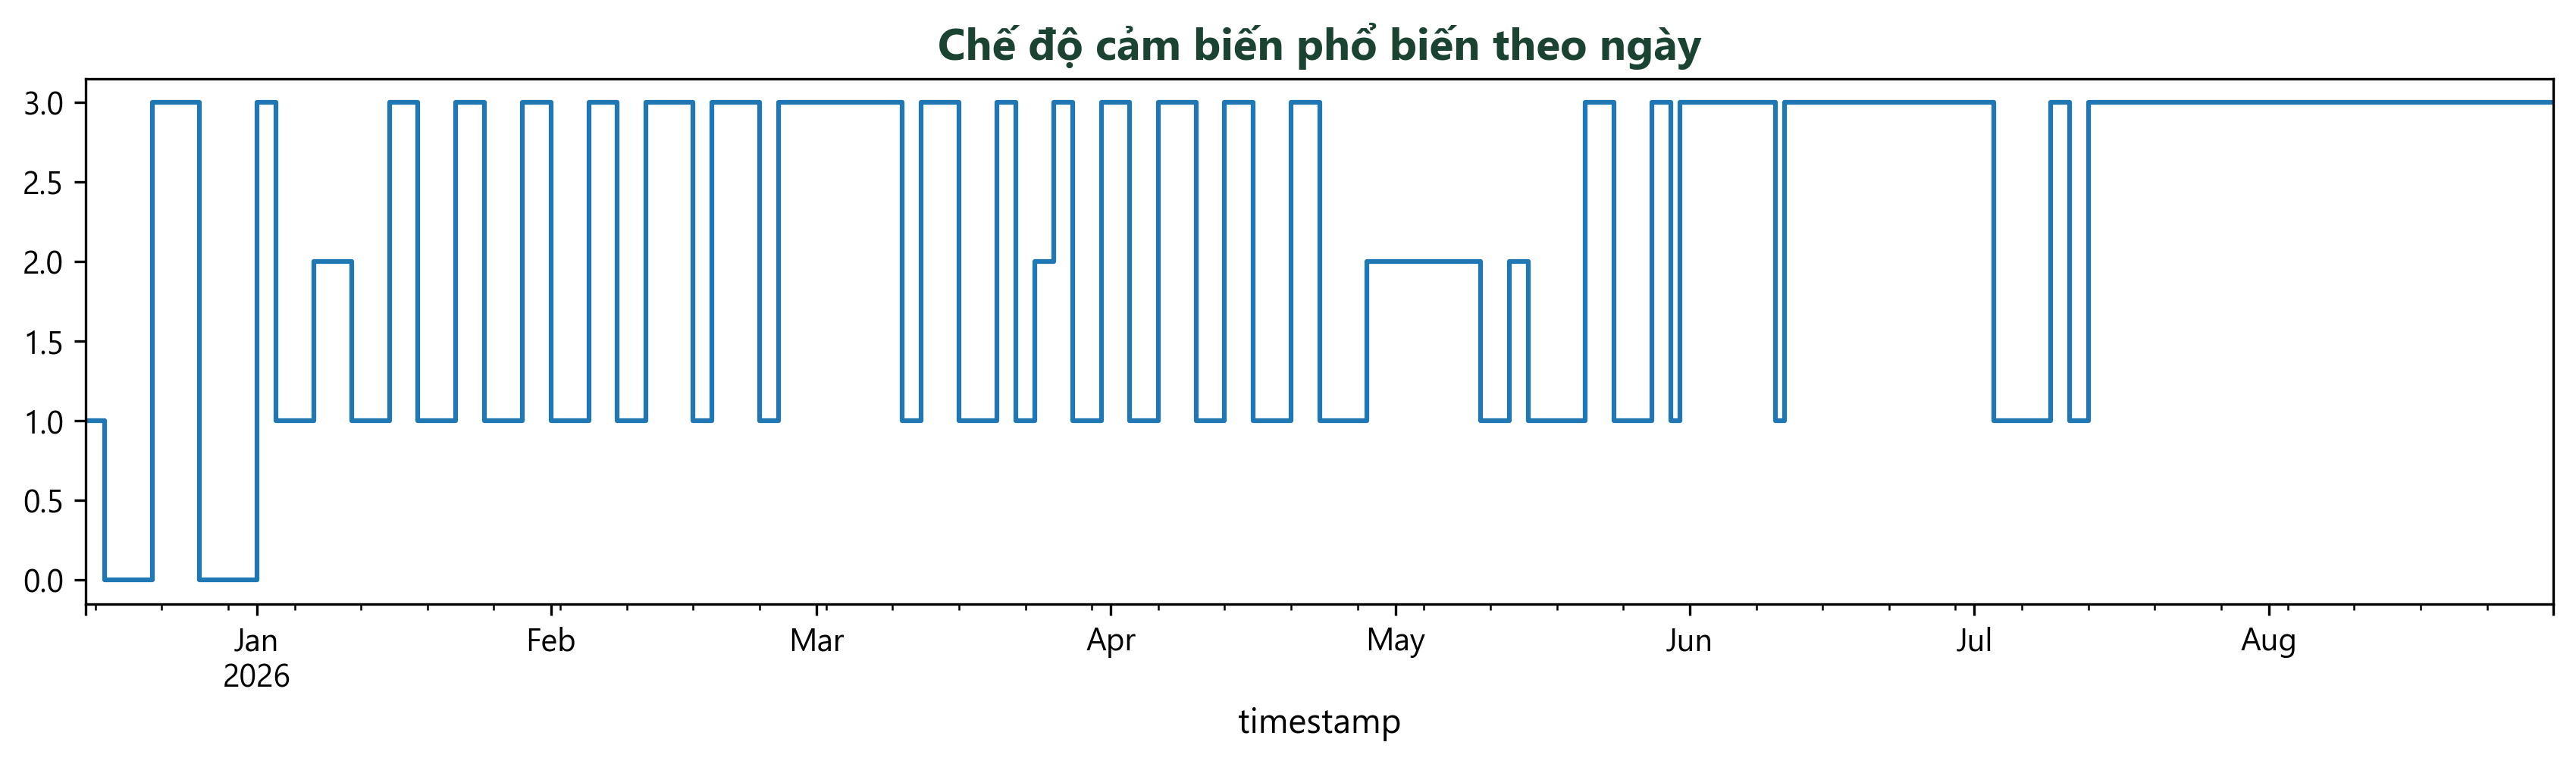

2    0.288549
3    0.273792
4    0.294821
5    0.314643
Name: daily silhouette, dtype: float64

daily_pattern_cluster
0     12
1     22
2     85
3      6
4    136
Name: days, dtype: int64

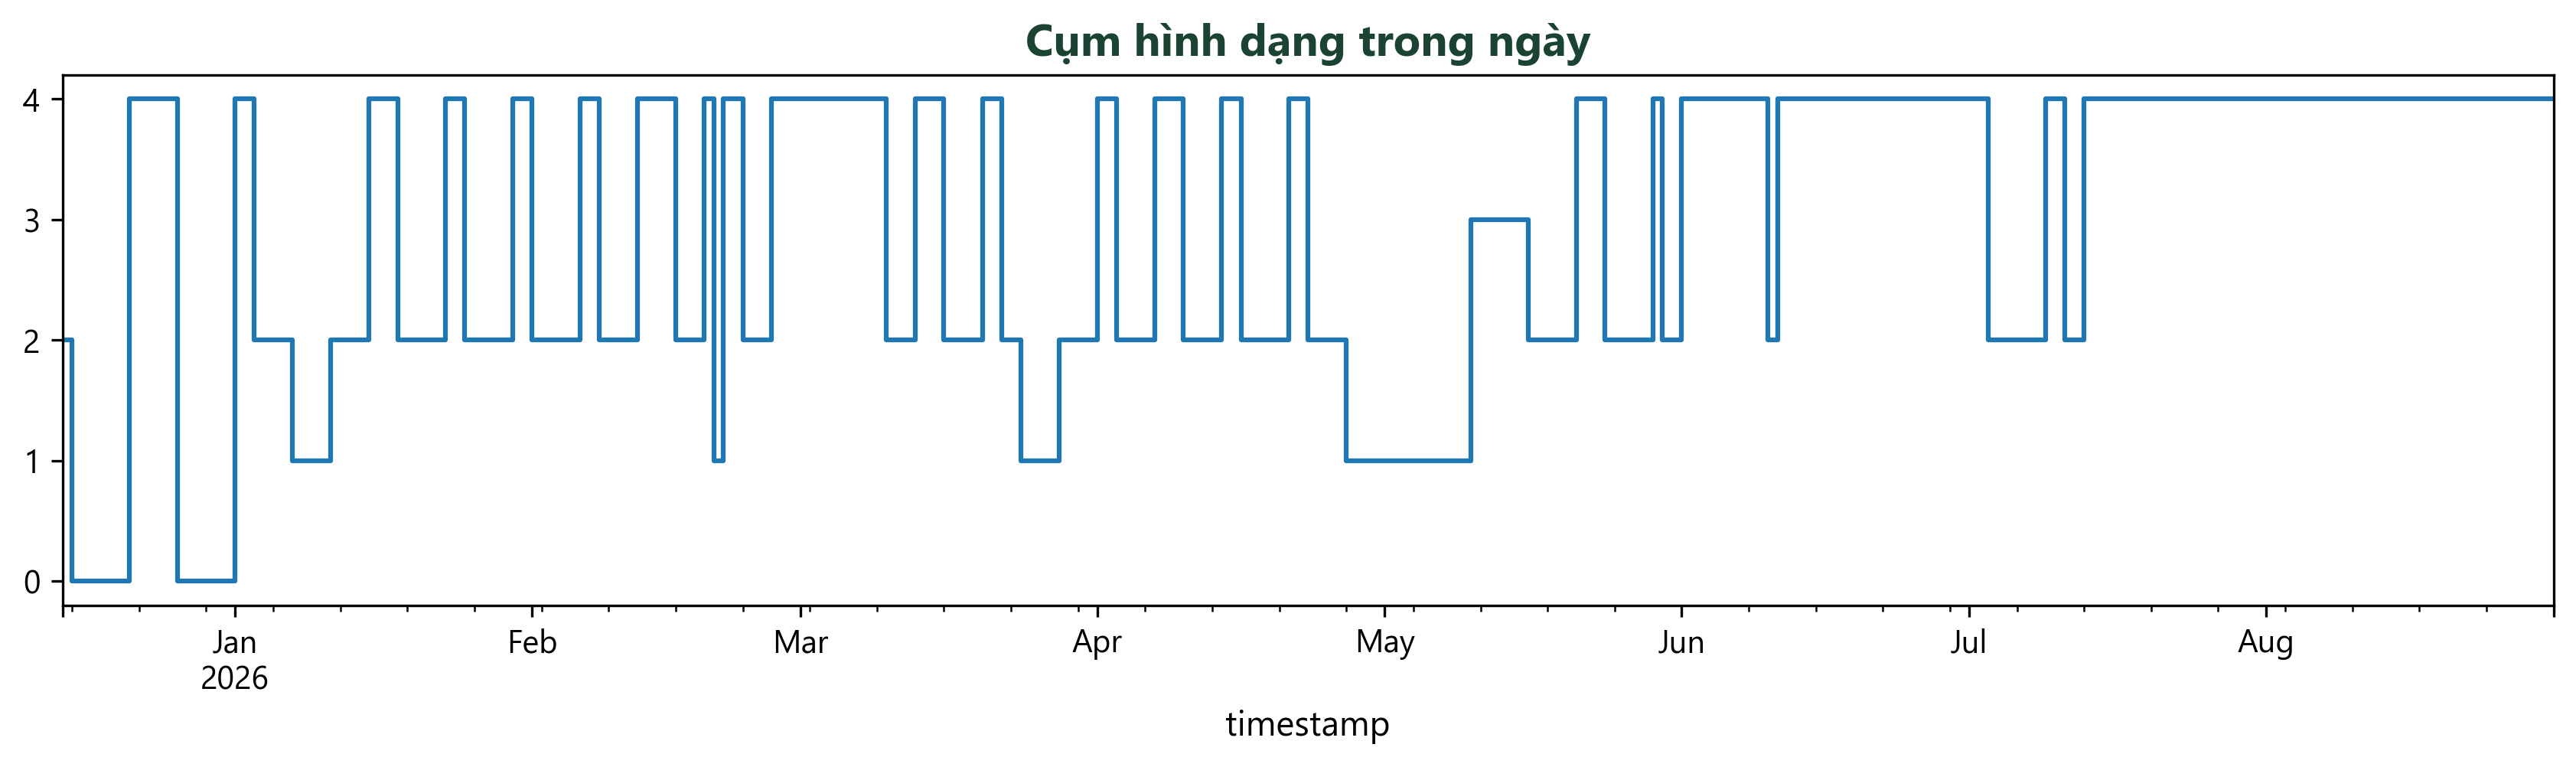

In [5]:
numeric = df.select_dtypes(include="number")

def choose_kmeans(data, max_k=6, sample_size=5000):
    data = data.replace([np.inf, -np.inf], np.nan).dropna()
    if len(data) < 3:
        raise ValueError("Không đủ hàng hợp lệ để phân cụm.")
    scaler = StandardScaler()
    x = scaler.fit_transform(data)
    rng = np.random.default_rng(RANDOM_STATE)
    sample_idx = rng.choice(len(x), min(sample_size, len(x)), replace=False)
    scores = {}
    for k in range(2, min(max_k, len(data) - 1) + 1):
        labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=10).fit_predict(x[sample_idx])
        if len(np.unique(labels)) > 1:
            scores[k] = silhouette_score(x[sample_idx], labels)
    best_k = max(scores, key=scores.get) if scores else 2
    model = KMeans(n_clusters=best_k, random_state=RANDOM_STATE, n_init=10).fit(x)
    return data, scaler, model, scores

cluster_data, cluster_scaler, regime_model, regime_scores = choose_kmeans(numeric, sample_size=4000)
regime_labels = pd.Series(regime_model.predict(cluster_scaler.transform(cluster_data)), index=cluster_data.index, name="regime")
regime_profiles = cluster_data.groupby(regime_labels).mean()
display(pd.Series(regime_scores, name="silhouette"))
display(regime_profiles)
regime_labels.resample("D").agg(lambda x: x.mode().iat[0] if not x.mode().empty else np.nan).plot(
    figsize=(14, 3), drawstyle="steps-post", title="Chế độ cảm biến phổ biến theo ngày"
)
plt.show()

daily_shape_per_day = numeric.groupby(numeric.index.normalize()).apply(
    lambda day: day.groupby(day.index.hour).mean().reindex(range(24)).interpolate(limit_direction="both").to_numpy().ravel()
)
daily_shape_per_day = pd.DataFrame(daily_shape_per_day.tolist(), index=pd.to_datetime(daily_shape_per_day.index))
daily_shape_per_day = daily_shape_per_day.dropna()
if len(daily_shape_per_day) >= 3:
    _, day_scaler, day_model, day_scores = choose_kmeans(daily_shape_per_day, max_k=5, sample_size=1000)
    daily_cluster = pd.Series(day_model.predict(day_scaler.transform(daily_shape_per_day)),
                              index=daily_shape_per_day.index, name="daily_pattern_cluster")
    display(pd.Series(day_scores, name="daily silhouette"))
    display(daily_cluster.value_counts().sort_index().rename("days"))
    daily_cluster.plot(figsize=(14, 3), drawstyle="steps-post", title="Cụm hình dạng trong ngày")
    plt.show()


## 5. Tương quan đơn biến/đa biến và PCA

Ma trận Pearson giúp rà soát tương quan tuyến tính đa biến; cặp có |r| lớn cần lưu ý đa cộng tuyến hoặc biến có quan hệ vật lý. Tương quan đơn biến theo độ trễ và tương quan với mục tiêu được trình bày riêng. PCA dùng dữ liệu đã nội suy để minh họa cấu trúc phương sai, không thay thế diễn giải miền nghiệp vụ.


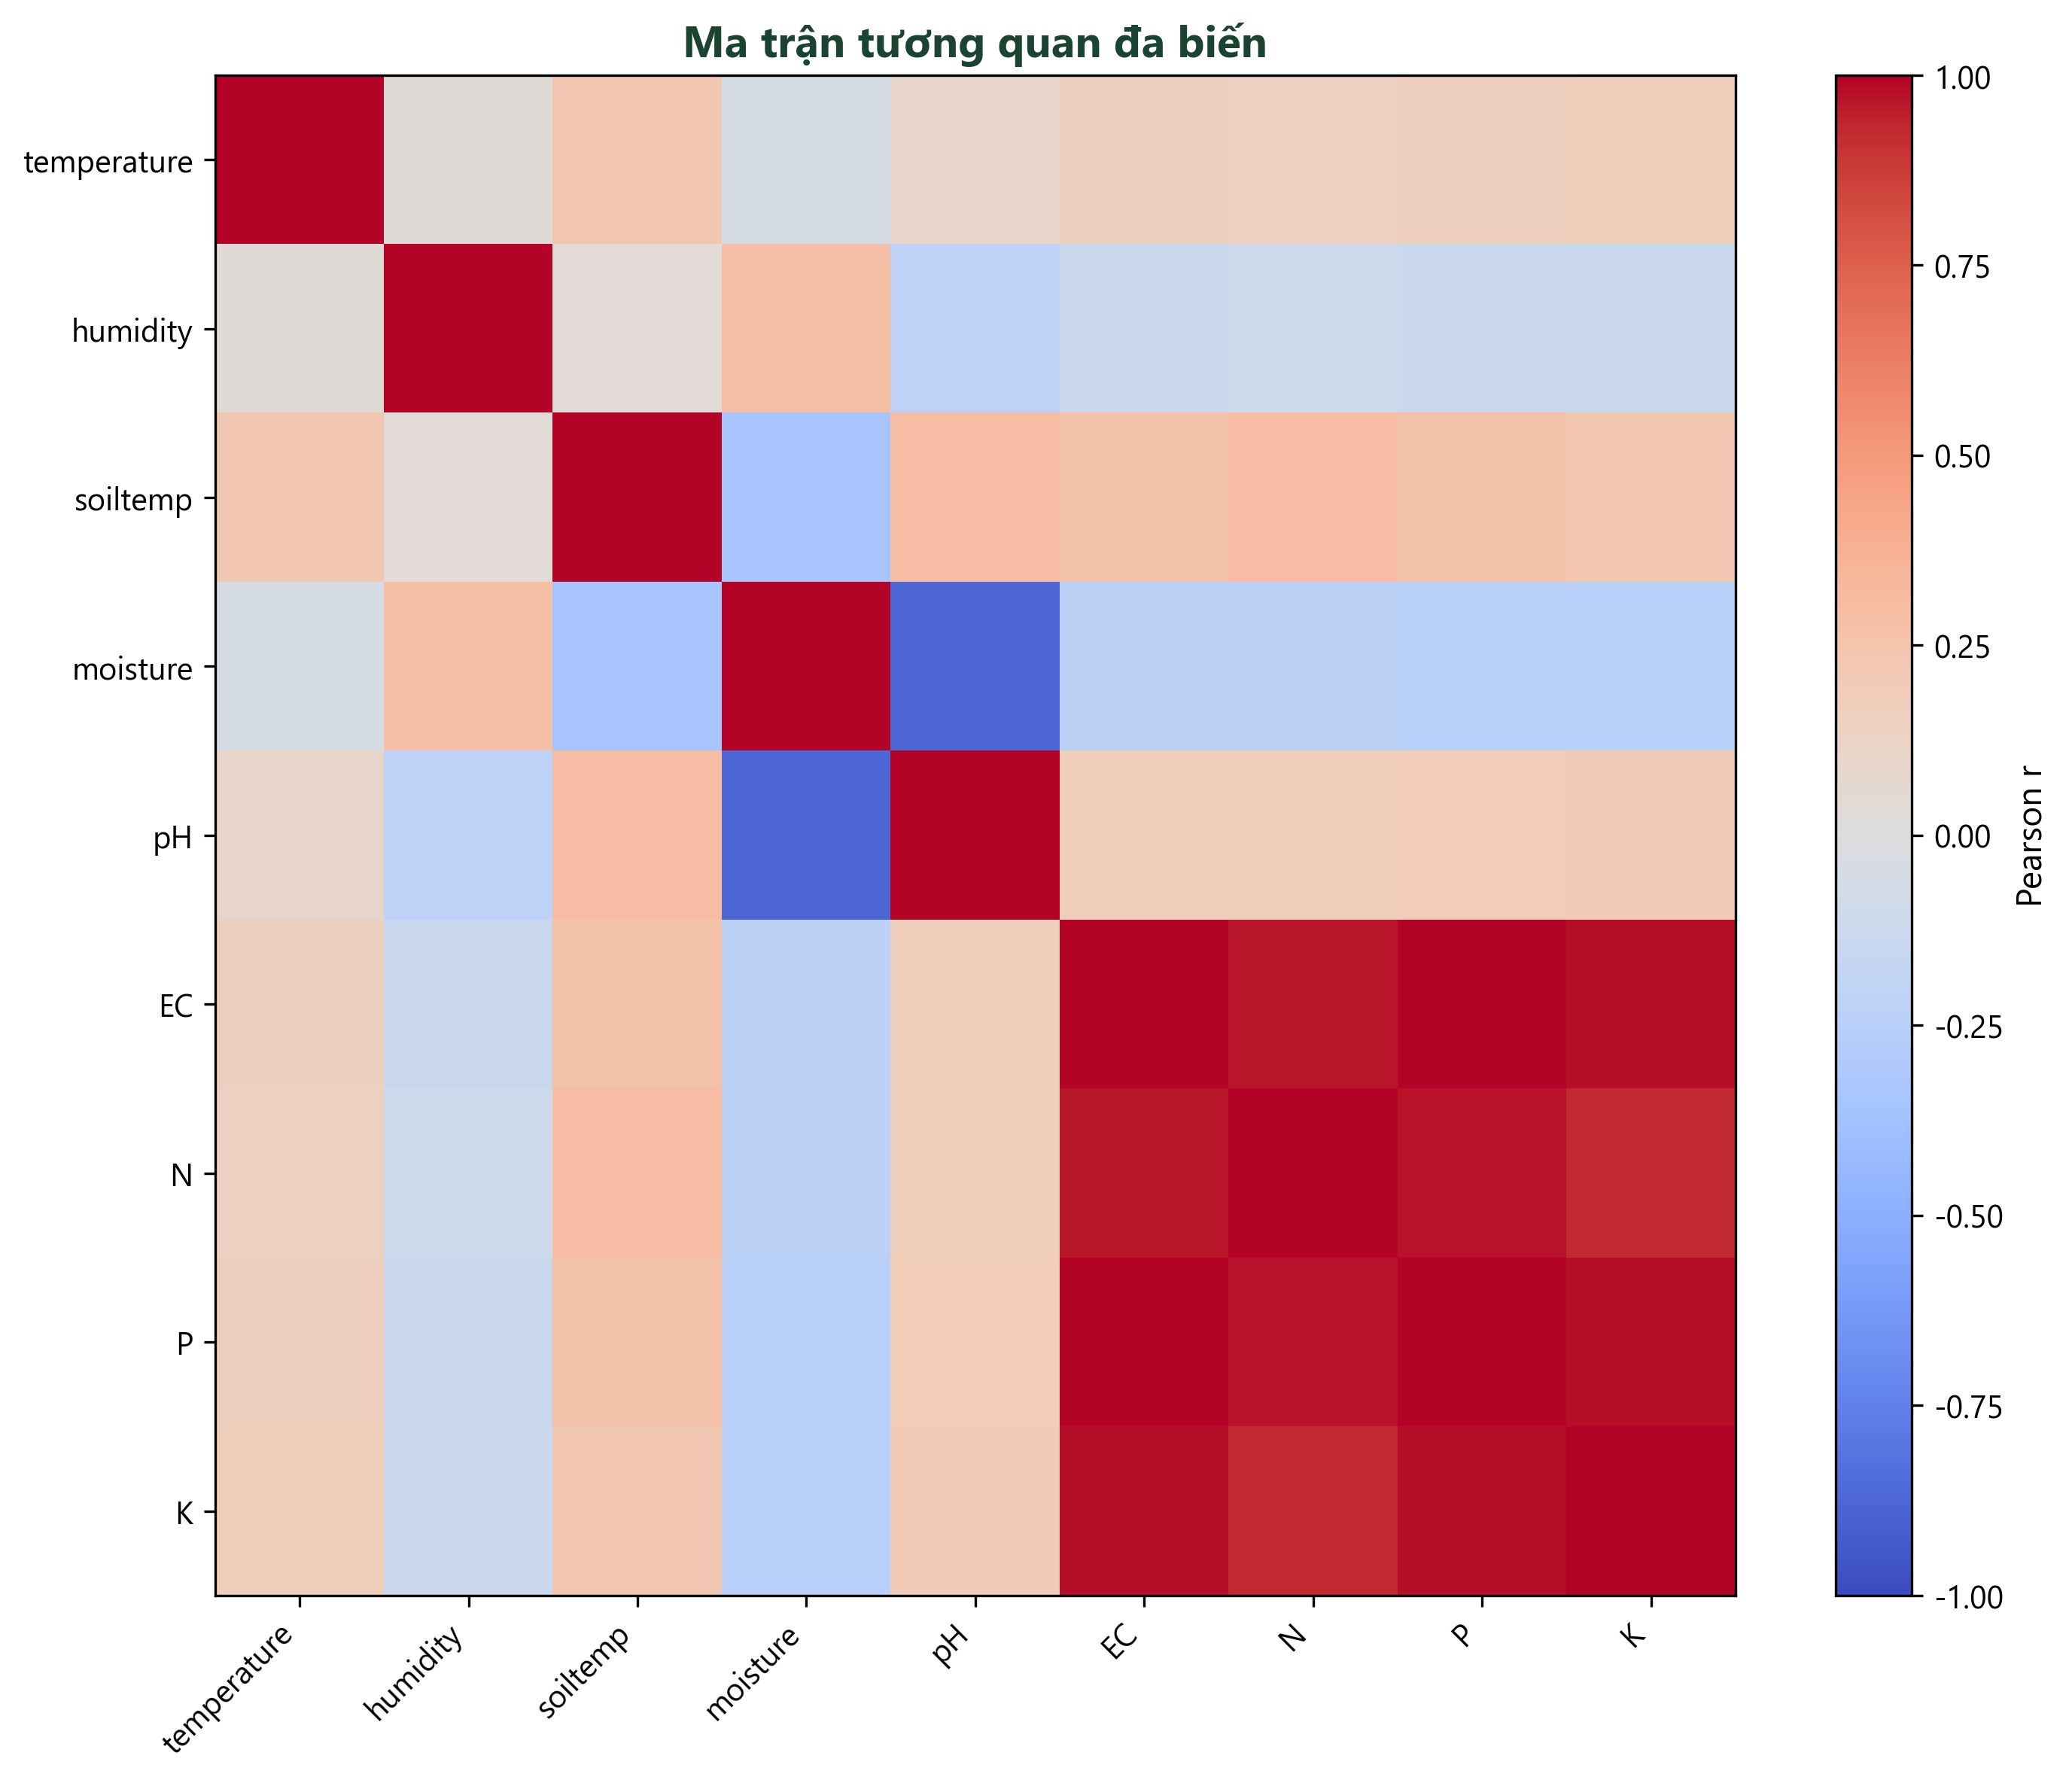

,variable_1,variable_2,correlation,abs_corr
31,EC,P,0.993862,0.993862
35,P,K,0.982112,0.982112
32,EC,K,0.981818,0.981818
33,N,P,0.969216,0.969216
30,EC,N,0.967448,0.967448
34,N,K,0.926473,0.926473
21,moisture,pH,-0.878620,0.878620
15,soiltemp,moisture,-0.348355,0.348355
18,soiltemp,N,0.292948,0.292948
16,soiltemp,pH,0.289574,0.289574


,corr_with_target
moisture,1.000000
pH,-0.878620
soiltemp,-0.348355
humidity,0.281847
K,-0.239160
P,-0.235698
EC,-0.222582
N,-0.220095
temperature,-0.061207


1      0.993836
2      0.992491
3      0.991198
6      0.987859
12     0.982202
24     0.971284
288    0.820556
Name: autocorrelation, dtype: float64

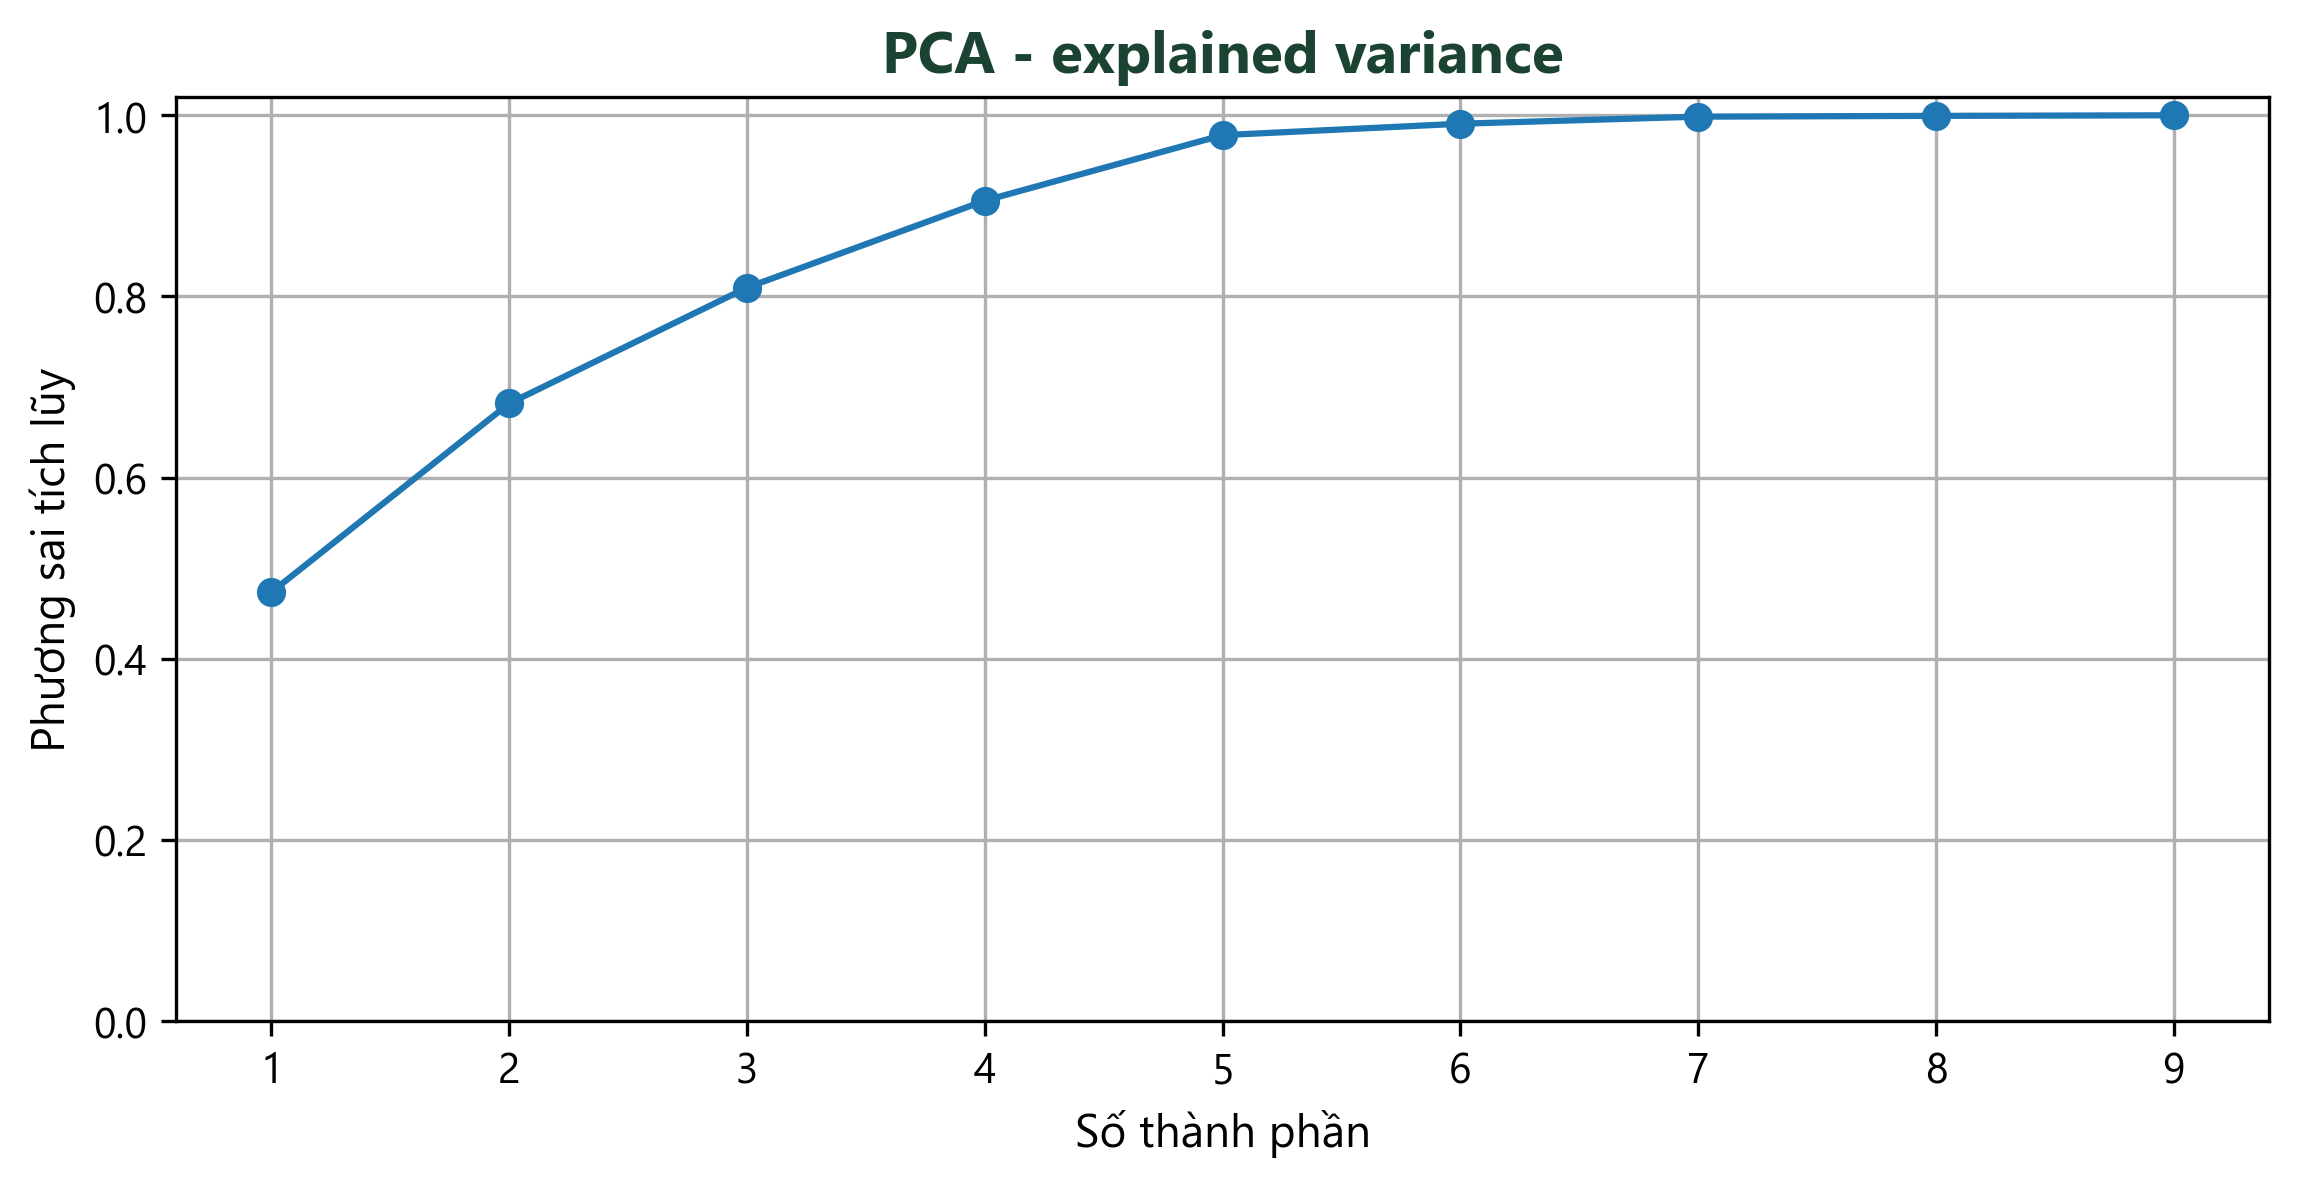

,PC1_loading,PC2_loading,PC3_loading
temperature,0.111477,0.040444,0.618160
humidity,-0.100961,-0.241840,0.564948
soiltemp,0.193306,0.237937,0.531730
moisture,-0.213021,-0.615160,0.059213
pH,0.185814,0.620304,-0.023826
EC,0.466715,-0.180566,-0.058251
N,0.458181,-0.174447,-0.028694
P,0.468391,-0.171233,-0.055204
K,0.461482,-0.166458,-0.068102


In [6]:
corr = numeric.corr()
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(corr, vmin=-1, vmax=1, cmap="coolwarm")
ax.set_xticks(range(len(corr.columns)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr.index)), corr.index)
fig.colorbar(im, ax=ax, label="Pearson r")
ax.set_title("Ma trận tương quan đa biến")
plt.tight_layout()
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack().rename("correlation").reset_index()
pairs.columns = ["variable_1", "variable_2", "correlation"]
display(pairs.assign(abs_corr=pairs.correlation.abs()).sort_values("abs_corr", ascending=False).head(15))
display(corr[TARGET].sort_values(key=lambda s: s.abs(), ascending=False).rename("corr_with_target").to_frame())

target_series = numeric[TARGET]
lag_corr = pd.Series({lag: target_series.corr(target_series.shift(lag)) for lag in [1, 2, 3, 6, 12, 24, 288]})
display(lag_corr.rename("autocorrelation"))

pca_input = numeric.interpolate(limit_direction="both").dropna()
pca_scaler = StandardScaler()
x_scaled = pca_scaler.fit_transform(pca_input)
pca = PCA().fit(x_scaled)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.arange(1, len(pca.explained_variance_ratio_) + 1),
        np.cumsum(pca.explained_variance_ratio_), marker="o")
ax.set(xlabel="Số thành phần", ylabel="Phương sai tích lũy", ylim=(0, 1.02), title="PCA - explained variance")
ax.grid(True)
plt.show()
display(pd.DataFrame(pca.components_[:3].T, index=pca_input.columns,
                     columns=["PC1_loading", "PC2_loading", "PC3_loading"] if len(pca.components_) >= 3
                     else [f"PC{i+1}_loading" for i in range(len(pca.components_))]))


## 6. Phương pháp xử lý khuyết, ngoại lệ và nhiễu

Các phương pháp dưới đây được minh họa/chẩn đoán trên dữ liệu, chưa tự động xóa hàng trong bảng gốc:

- Khuyết: median, forward-fill (chỉ dùng quá khứ), nội suy thời gian (mô tả EDA), KNN với khoảng cách nan-Euclidean, và IterativeImputer (MICE-style).
- Ngoại lệ: Z-score, IQR, Isolation Forest, DBSCAN (trên mẫu và dữ liệu chuẩn hóa). Z-score/IQR là ngưỡng đơn biến; Isolation Forest/DBSCAN xét cấu trúc đa biến. Cờ ngoại lệ không đồng nghĩa lỗi đo.
- Xử lý: xóa/trim chỉ khi có căn cứ và không phá mất chuỗi; capping/winsorization; biến đổi Yeo-Johnson cho dữ liệu âm/dương. Không dùng log trực tiếp khi có giá trị không dương.
- Nhiễu: binning theo khung thời gian và moving average. Làm trơn làm đổi mục tiêu/thời điểm và có thể che đỉnh; phần benchmark chỉ sử dụng trung bình lùi (causal) trên biến dự báo.


c:\Program Files\Python312\Lib\site-packages\sklearn\impute\_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


Imputation demos (median, forward fill, KNN nan-euclidean, MICE): (4000, 9) (4000, 9) (4000, 9) (4000, 9)
Outlier counts: Z-score rows= 262 IQR rows= 668 Isolation Forest rows= 563 DBSCAN sample noise= 5
Capping rows=4,000; trim rows=3,670; Yeo-Johnson=(4000, 9); binning=(4000, 9)


c:\Program Files\Python312\Lib\site-packages\sklearn\preprocessing\_discretization.py:296: FutureWarning: The current default behavior, quantile_method='linear', will be changed to quantile_method='averaged_inverted_cdf' in scikit-learn version 1.9 to naturally support sample weight equivalence properties by default. Pass quantile_method='averaged_inverted_cdf' explicitly to silence this warning.
  warnings.warn(


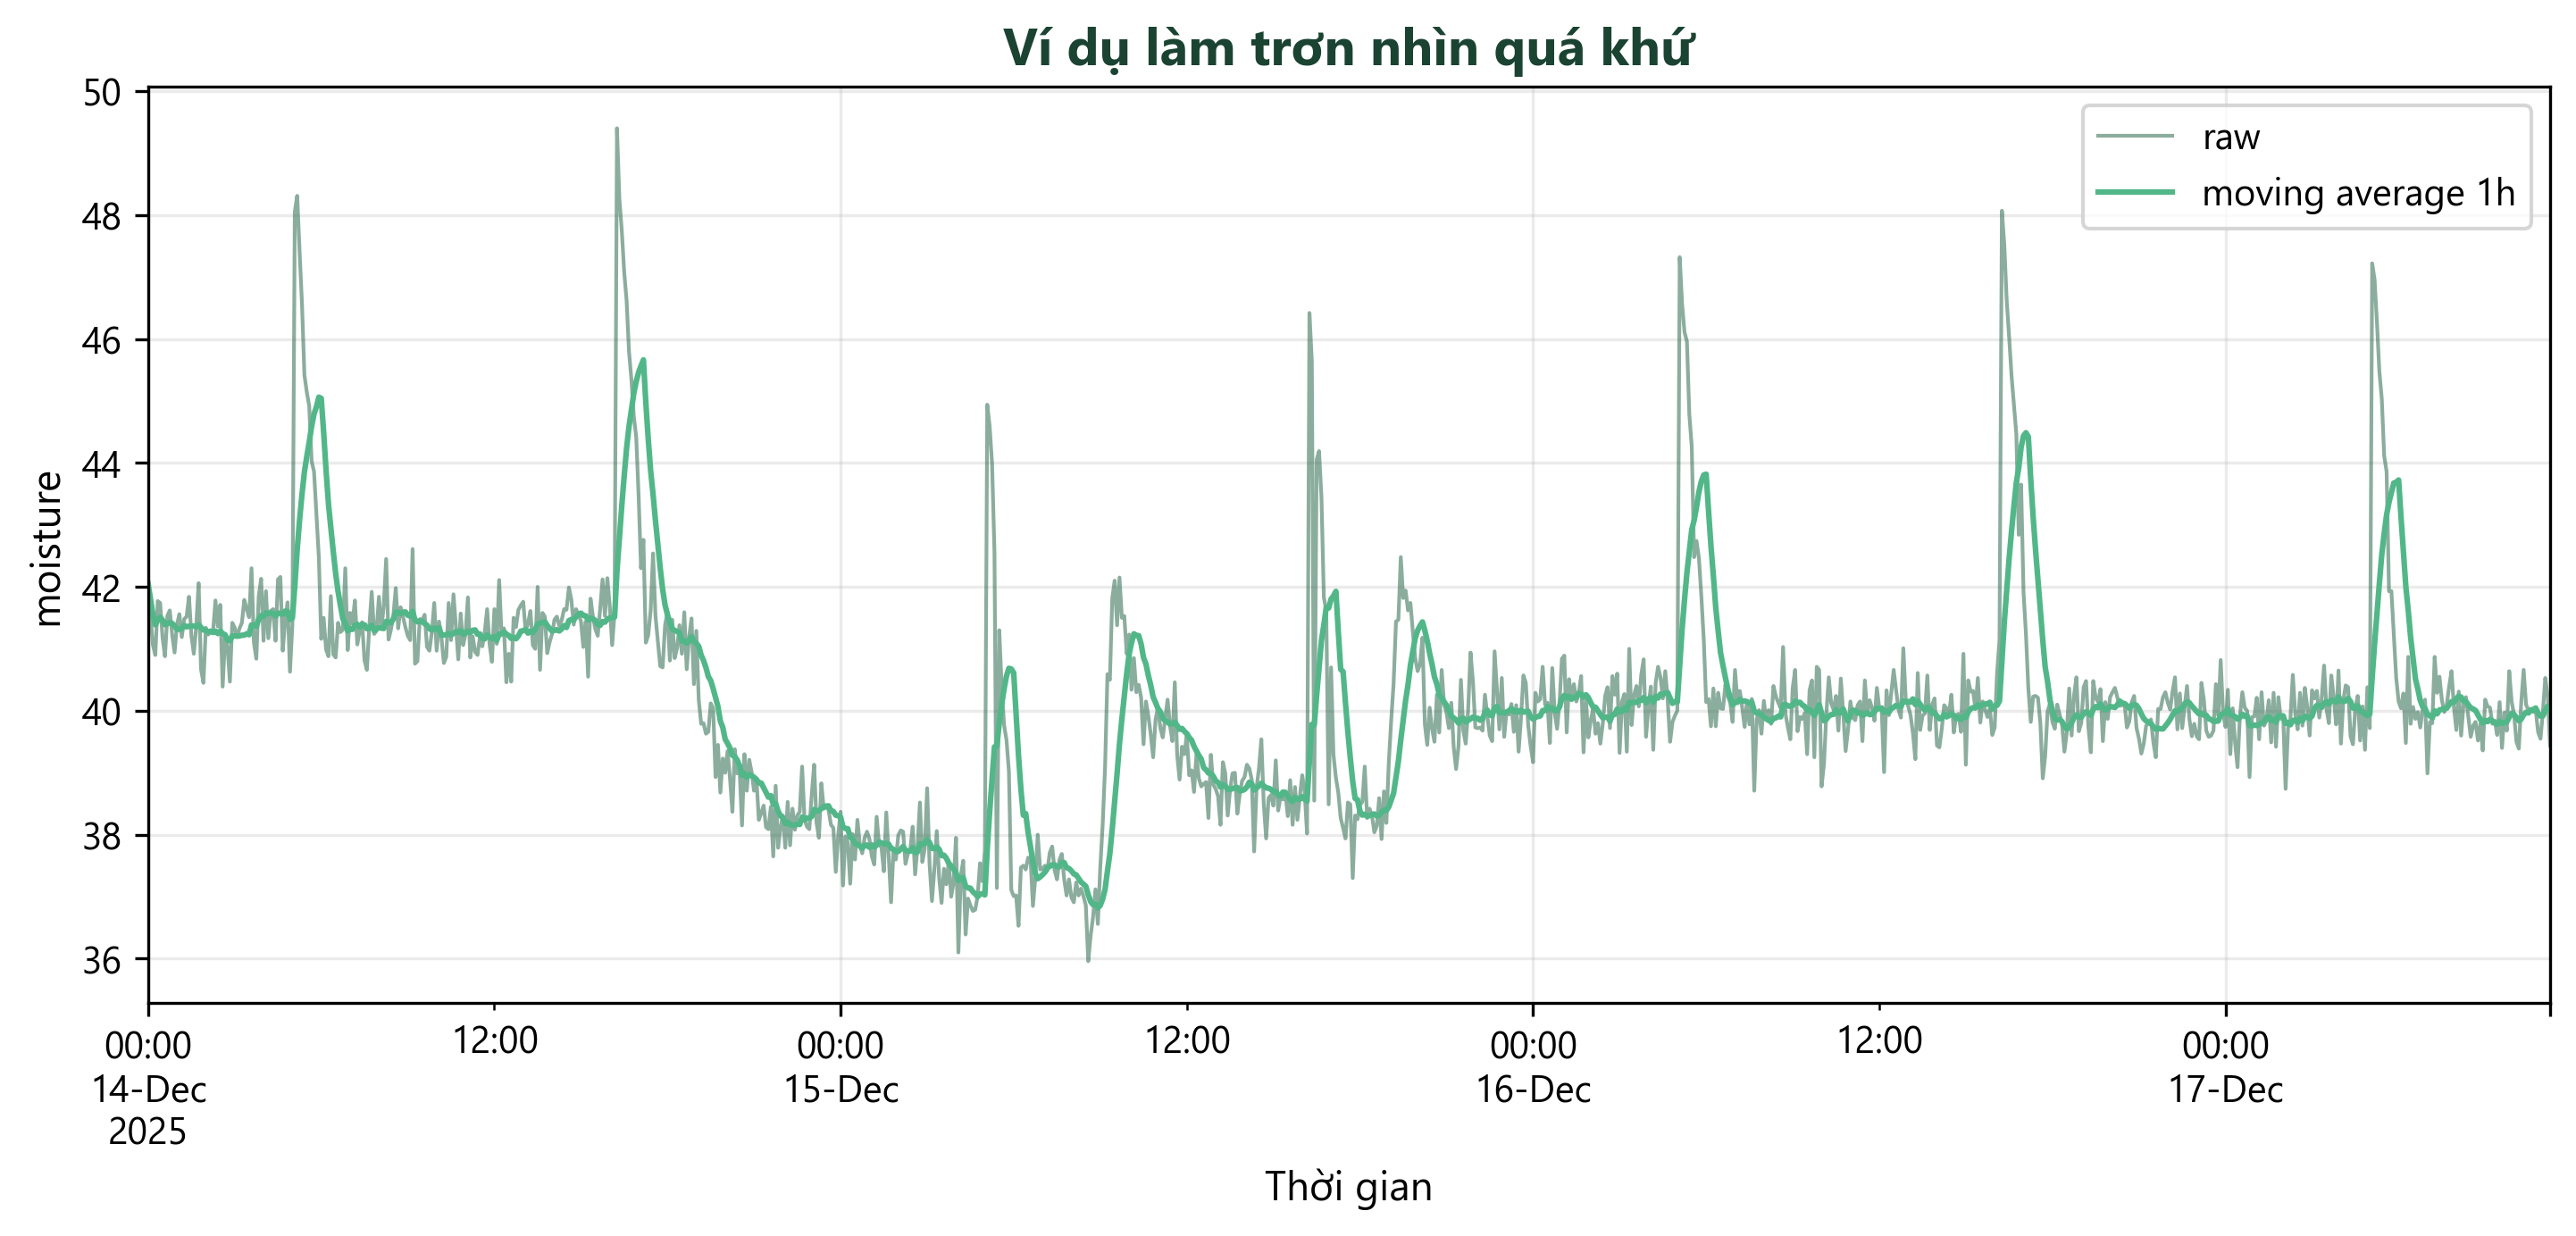

In [7]:
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.ensemble import IsolationForest
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import KBinsDiscretizer
from sklearn.cluster import DBSCAN

# Demonstrate missing-value methods on a bounded sample; KNN uses nan-euclidean distance.
features = numeric.columns.tolist()
x_raw = numeric.copy()
demo_rows = np.linspace(0, len(x_raw) - 1, min(4000, len(x_raw)), dtype=int)
x_demo = x_raw.iloc[demo_rows]
demo_split = max(1, int(len(x_demo) * .75))
median_demo = SimpleImputer(strategy="median").fit(x_demo.iloc[:demo_split]).transform(x_demo)
ffill_demo = x_demo.ffill().fillna(x_demo.iloc[:demo_split].median())
knn_demo = KNNImputer(n_neighbors=5, metric="nan_euclidean").fit(x_demo.iloc[:demo_split]).transform(x_demo)
mice_demo = IterativeImputer(max_iter=5, random_state=RANDOM_STATE).fit_transform(x_demo)
print("Imputation demos (median, forward fill, KNN nan-euclidean, MICE):", median_demo.shape, ffill_demo.shape, knn_demo.shape, mice_demo.shape)

# Outlier diagnostics; detectors identify candidates but do not assume every outlier is an error.
complete = pd.DataFrame(median_demo, index=x_demo.index, columns=features)
z_flags = ((complete - complete.mean()).abs() / complete.std(ddof=0)).gt(3)
q1, q3 = complete.quantile(.25), complete.quantile(.75)
iqr = q3 - q1
iqr_flags = complete.lt(q1 - 1.5 * iqr) | complete.gt(q3 + 1.5 * iqr)
x_out_scaled = StandardScaler().fit_transform(complete)
iforest_flags = IsolationForest(contamination="auto", random_state=RANDOM_STATE, n_estimators=100, n_jobs=1).fit_predict(x_out_scaled) == -1
sample_idx = np.linspace(0, len(complete) - 1, min(2000, len(complete)), dtype=int)
dbscan_flags = DBSCAN(eps=2.5, min_samples=10).fit_predict(x_out_scaled[sample_idx]) == -1
print("Outlier counts: Z-score rows=", int(z_flags.any(axis=1).sum()),
      "IQR rows=", int(iqr_flags.any(axis=1).sum()),
      "Isolation Forest rows=", int(iforest_flags.sum()),
      "DBSCAN sample noise=", int(dbscan_flags.sum()))

lower, upper = complete.quantile(.01), complete.quantile(.99)
capped_demo = complete.clip(lower=lower, upper=upper, axis="columns")
trimmed_demo = complete.mask(((complete < lower) | (complete > upper)).any(axis=1)).dropna()
yeo_demo = PowerTransformer(method="yeo-johnson", standardize=False).fit_transform(complete)
binned_demo = KBinsDiscretizer(n_bins=10, encode="ordinal", strategy="quantile", subsample=2000, random_state=RANDOM_STATE).fit_transform(complete)
print(f"Capping rows={len(capped_demo):,}; trim rows={len(trimmed_demo):,}; Yeo-Johnson={yeo_demo.shape}; binning={binned_demo.shape}")

# Causal moving average: only current and preceding observations are used.
daily_binned = numeric.resample("D").mean()
moving_average = numeric.rolling(window=12, min_periods=1).mean()
fig, ax = plt.subplots(figsize=(9.5, 4.5), dpi=300, constrained_layout=True)
numeric[TARGET].iloc[:1000].plot(ax=ax, alpha=.55, label="raw", color="#2D6A4F", linewidth=1)
moving_average[TARGET].iloc[:1000].plot(ax=ax, label="moving average 1h", color="#52B788", linewidth=1.5)
ax.legend()
ax.set_title("Ví dụ làm trơn nhìn quá khứ")
ax.set_xlabel("Thời gian")
ax.set_ylabel(TARGET)
ax.grid(alpha=0.25)
plt.show()


## 7. Benchmark phương pháp riêng lẻ và kết hợp

Benchmark gồm hai phần để vừa thấy tác động của từng kỹ thuật, vừa kiểm tra các pipeline kết hợp:

1. **Phương pháp riêng lẻ**: từng cách điền khuyết, xử lý ngoại lệ hoặc giảm nhiễu được chạy như một candidate độc lập.
2. **Pipeline kết hợp**: áp dụng tuần tự nhiều bước trong cùng một candidate, ví dụ `median -> IQR capping -> moving average` hoặc `KNN -> Z-score capping -> Yeo-Johnson`.

Mỗi candidate được fit trên phần train theo thời gian; validation/test dùng cùng mốc và giữ nguyên hàng đánh giá. Imputer, ngưỡng capping, bộ biến đổi và bộ chia bin chỉ được fit từ train. Trim/loại ngoại lệ chỉ loại hàng train. Moving average là cửa sổ lùi 1 giờ, không dùng dữ liệu tương lai.

Chia theo thời gian theo tỷ lệ **80:20**: 80% đầu là tập phát triển và 20% cuối là test giữ lại. Bên trong 80% tập phát triển, tiếp tục chia theo thời gian thành 80% train và 20% validation (tương ứng toàn bộ dữ liệu là 64% train, 16% validation, 20% test). Validation dùng chọn candidate; test chỉ dùng đánh giá cuối.

Bài toán dự báo `TARGET` sau 5 phút. XGBoost và LSTM được benchmark trên cùng train/validation/test. Xem MAE validation để xếp hạng; dùng metric test để xác nhận khả năng tổng quát hóa.


In [8]:
data = numeric.copy()
data = data.asfreq(FREQUENCY)
supervised = data.copy()
supervised["__target__"] = data[TARGET].shift(-1)
supervised = supervised.iloc[:-1]
n = len(supervised)

# Hold out the last 20% for the final test. Split the first 80% chronologically
# into train/validation so model and preprocessing choices do not use test data.
test_start = int(n * 0.80)
development = supervised.iloc[:test_start]
train_end = int(len(development) * 0.80)
train_raw = development.iloc[:train_end]
val_raw = development.iloc[train_end:]
test_raw = supervised.iloc[test_start:]
print(
    f"Train={len(train_raw):,} ({len(train_raw)/n:.1%}), "
    f"validation={len(val_raw):,} ({len(val_raw)/n:.1%}), "
    f"train+validation={len(development):,} ({len(development)/n:.1%}), "
    f"test={len(test_raw):,} ({len(test_raw)/n:.1%})"
)


Train=48,106 (64.0%), validation=12,027 (16.0%), train+validation=60,133 (80.0%), test=15,034 (20.0%)


In [9]:
def fit_transform_pair(method, train_x, later_x):
    sample_idx = np.linspace(0, len(train_x) - 1, min(1000, len(train_x)), dtype=int)
    fit_sample = train_x.iloc[sample_idx].copy()
    if method == "median":
        imputer = SimpleImputer(strategy="median")
        imputer.fit(fit_sample)
        train_values = imputer.transform(train_x)
        later_values = imputer.transform(later_x)
    elif method == "ffill":
        combined = pd.concat([train_x, later_x]).ffill()
        train_values = combined.loc[train_x.index].to_numpy()
        later_values = combined.loc[later_x.index].to_numpy()
        fallback = train_x.median()
        train_values = pd.DataFrame(train_values, index=train_x.index, columns=train_x.columns).fillna(fallback).to_numpy()
        later_values = pd.DataFrame(later_values, index=later_x.index, columns=later_x.columns).fillna(fallback).to_numpy()
    elif method in ("knn", "mice"):
        scaler = StandardScaler()
        fit_scaled = scaler.fit_transform(fit_sample)
        train_scaled = scaler.transform(train_x)
        later_scaled = scaler.transform(later_x)
        if method == "knn":
            imputer = KNNImputer(n_neighbors=5, metric="nan_euclidean", weights="distance")
        else:
            imputer = IterativeImputer(max_iter=3, random_state=RANDOM_STATE, sample_posterior=False)
        imputer.fit(fit_scaled)
        train_values = scaler.inverse_transform(imputer.transform(train_scaled))
        later_values = scaler.inverse_transform(imputer.transform(later_scaled))
    else:
        raise ValueError(f"Unsupported imputation: {method}")
    return (
        pd.DataFrame(train_values, index=train_x.index, columns=train_x.columns),
        pd.DataFrame(later_values, index=later_x.index, columns=later_x.columns),
    )


def metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "R2": r2_score(y_true, y_pred),
    }

LOOKBACK = 12
EPOCHS = 5
BATCH_SIZE = 256
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"


def make_sequences(x, y, lookback):
    x_values = np.asarray(x, dtype=np.float32)
    y_values = np.asarray(y, dtype=np.float32)
    windows = np.stack([
        x_values[i - lookback + 1:i + 1]
        for i in range(lookback - 1, len(x_values))
    ])
    return windows, y_values[lookback - 1:]


class LSTMRegressor(nn.Module):
    def __init__(self, n_features, hidden_size=32):
        super().__init__()
        self.lstm = nn.LSTM(n_features, hidden_size, batch_first=True)
        self.head = nn.Linear(hidden_size, 1)

    def forward(self, x):
        output, _ = self.lstm(x)
        return self.head(output[:, -1, :]).squeeze(-1)


NameError: name 'torch' is not defined

In [ ]:
feature_cols = data.columns.tolist()
y_train = train_raw["__target__"].to_numpy()
y_val = val_raw["__target__"].to_numpy()
y_test = test_raw["__target__"].to_numpy()
val_target_mask = np.isfinite(y_val)
test_target_mask = np.isfinite(y_test)

results = []
predictions = {}


def add_candidate(candidate, family, x_train_df, x_val_df, x_test_df, train_keep=None):
    if train_keep is None:
        train_keep = np.ones(len(x_train_df), dtype=bool)
    else:
        train_keep = np.asarray(train_keep, dtype=bool)
    xgb_train_mask = train_keep & np.isfinite(y_train)
    if xgb_train_mask.sum() == 0:
        raise ValueError(f"No usable training rows for {candidate}")

    xgb = XGBRegressor(
        n_estimators=250, max_depth=6, learning_rate=.05,
        subsample=.8, colsample_bytree=.8, objective="reg:squarederror",
        random_state=RANDOM_STATE, n_jobs=4,
    )
    xgb.fit(
        x_train_df.loc[xgb_train_mask], y_train[xgb_train_mask],
        eval_set=[(x_val_df.loc[val_target_mask], y_val[val_target_mask])],
        verbose=False,
    )
    val_pred = xgb.predict(x_val_df)
    test_pred = xgb.predict(x_test_df)
    results.append({
        "family": family, "method": candidate, "model": "XGBoost",
        **metrics(y_val[val_target_mask], val_pred[val_target_mask]),
        **{f"test_{key}": value for key, value in metrics(y_test[test_target_mask], test_pred[test_target_mask]).items()},
        "train_rows_used": int(xgb_train_mask.sum()),
    })
    predictions[(candidate, "XGBoost")] = (val_pred, test_pred)

    # Fit feature scaling on retained training rows only.
    scaler = StandardScaler()
    scaler.fit(x_train_df.loc[train_keep])
    x_train = scaler.transform(x_train_df).astype(np.float32)
    x_val = scaler.transform(x_val_df).astype(np.float32)
    x_test = scaler.transform(x_test_df).astype(np.float32)

    target_mean = np.nanmean(y_train[train_keep])
    target_std = np.nanstd(y_train[train_keep])
    if not np.isfinite(target_std) or target_std == 0:
        raise ValueError(f"Invalid target scale for {candidate}")
    train_windows, train_targets = make_sequences(
        x_train, (y_train - target_mean) / target_std, LOOKBACK
    )
    window_keep = train_keep[LOOKBACK - 1:] & np.isfinite(train_targets)
    train_windows = train_windows[window_keep]
    train_targets = train_targets[window_keep]

    torch.manual_seed(RANDOM_STATE)
    lstm = LSTMRegressor(x_train.shape[1]).to(DEVICE)
    loader = DataLoader(
        TensorDataset(torch.from_numpy(train_windows), torch.from_numpy(train_targets)),
        batch_size=BATCH_SIZE, shuffle=False,
    )
    optimizer = torch.optim.Adam(lstm.parameters(), lr=1e-3)
    loss_fn = nn.MSELoss()
    lstm.train()
    for _ in range(EPOCHS):
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss_fn(lstm(xb), yb).backward()
            optimizer.step()

    def predict_lstm(eval_x, preceding):
        context = np.concatenate([preceding[-(LOOKBACK - 1):], eval_x]).astype(np.float32)
        windows = np.stack([context[i:i + LOOKBACK] for i in range(len(eval_x))])
        lstm.eval()
        with torch.no_grad():
            scaled_prediction = lstm(torch.from_numpy(windows).to(DEVICE)).cpu().numpy()
        return scaled_prediction * target_std + target_mean

    val_lstm_pred = predict_lstm(x_val, x_train)
    test_lstm_pred = predict_lstm(x_test, np.concatenate([x_train, x_val]))
    results.append({
        "family": family, "method": candidate, "model": "LSTM",
        **metrics(y_val[val_target_mask], val_lstm_pred[val_target_mask]),
        **{f"test_{key}": value for key, value in metrics(y_test[test_target_mask], test_lstm_pred[test_target_mask]).items()},
        "train_rows_used": int(window_keep.sum()),
    })
    predictions[(candidate, "LSTM")] = (val_lstm_pred, test_lstm_pred)


# Compare each missing-data method as a separate candidate.
for method in ["median", "ffill", "knn", "mice"]:
    x_train_df, x_val_df = fit_transform_pair(method, train_raw[feature_cols], val_raw[feature_cols])
    _, x_test_df = fit_transform_pair(method, train_raw[feature_cols], test_raw[feature_cols])
    add_candidate(
        candidate=method, family="missing_value",
        x_train_df=x_train_df, x_val_df=x_val_df, x_test_df=x_test_df,
    )

# For non-missing interventions, median imputation is the shared complete-data reference.
# Exactly one intervention below is applied for each candidate.
x_train_base, x_val_base = fit_transform_pair("median", train_raw[feature_cols], val_raw[feature_cols])
_, x_test_base = fit_transform_pair("median", train_raw[feature_cols], test_raw[feature_cols])


def add_from_base(candidate, train_x, val_x, test_x, train_keep=None):
    add_candidate(
        candidate=candidate, family="outlier_noise_transform",
        x_train_df=train_x, x_val_df=val_x, x_test_df=test_x,
        train_keep=train_keep,
    )


# Z-score and IQR are benchmarked separately as train-row trimming OR feature capping.
z_mean = x_train_base.mean()
z_std = x_train_base.std(ddof=0).replace(0, 1)
z_lower, z_upper = z_mean - 3 * z_std, z_mean + 3 * z_std
z_train_outlier = x_train_base.lt(z_lower) | x_train_base.gt(z_upper)
add_from_base("zscore_trim", x_train_base, x_val_base, x_test_base,
              train_keep=~z_train_outlier.any(axis=1).to_numpy())
add_from_base("zscore_cap", x_train_base.clip(z_lower, z_upper, axis="columns"),
              x_val_base.clip(z_lower, z_upper, axis="columns"),
              x_test_base.clip(z_lower, z_upper, axis="columns"))

iqr_q1, iqr_q3 = x_train_base.quantile(.25), x_train_base.quantile(.75)
iqr_width = (iqr_q3 - iqr_q1).replace(0, 1)
iqr_lower, iqr_upper = iqr_q1 - 1.5 * iqr_width, iqr_q3 + 1.5 * iqr_width
iqr_outlier = x_train_base.lt(iqr_lower) | x_train_base.gt(iqr_upper)
add_from_base("iqr_trim", x_train_base, x_val_base, x_test_base,
              train_keep=~iqr_outlier.any(axis=1).to_numpy())
add_from_base("iqr_cap", x_train_base.clip(iqr_lower, iqr_upper, axis="columns"),
              x_val_base.clip(iqr_lower, iqr_upper, axis="columns"),
              x_test_base.clip(iqr_lower, iqr_upper, axis="columns"))

# Detector-based deletion affects training rows only; validation and test remain identical.
outlier_scaler = StandardScaler().fit(x_train_base)
x_train_scaled = outlier_scaler.transform(x_train_base)
iforest = IsolationForest(contamination="auto", random_state=RANDOM_STATE, n_estimators=100, n_jobs=1)
iforest.fit(x_train_scaled)
iforest_keep = iforest.predict(x_train_scaled) != -1
add_from_base("isolation_forest_train_trim", x_train_base, x_val_base, x_test_base,
              train_keep=iforest_keep)

rng = np.random.default_rng(RANDOM_STATE)
dbscan_sample_idx = np.sort(rng.choice(len(x_train_base), min(8000, len(x_train_base)), replace=False))
dbscan = __import__("sklearn.cluster", fromlist=["DBSCAN"]).DBSCAN(eps=2.5, min_samples=10)
dbscan_labels = dbscan.fit_predict(x_train_scaled[dbscan_sample_idx])
dbscan_keep = np.ones(len(x_train_base), dtype=bool)
dbscan_keep[dbscan_sample_idx] = dbscan_labels != -1
add_from_base("dbscan_train_noise_trim", x_train_base, x_val_base, x_test_base,
              train_keep=dbscan_keep)

# Yeo-Johnson is fitted only on training features.
power = PowerTransformer(method="yeo-johnson", standardize=False)
power.fit(x_train_base)
add_from_base(
    "yeo_johnson", pd.DataFrame(power.transform(x_train_base), index=x_train_base.index, columns=feature_cols),
    pd.DataFrame(power.transform(x_val_base), index=x_val_base.index, columns=feature_cols),
    pd.DataFrame(power.transform(x_test_base), index=x_test_base.index, columns=feature_cols),
)

# Quantile binning is a standalone 10-bin discretization candidate.
binner = __import__("sklearn.preprocessing", fromlist=["KBinsDiscretizer"]).KBinsDiscretizer(
    n_bins=10, encode="ordinal", strategy="quantile", subsample=20000, random_state=RANDOM_STATE,
)
binner.fit(x_train_base)
add_from_base(
    "quantile_binning_10", pd.DataFrame(binner.transform(x_train_base), index=x_train_base.index, columns=feature_cols),
    pd.DataFrame(binner.transform(x_val_base), index=x_val_base.index, columns=feature_cols),
    pd.DataFrame(binner.transform(x_test_base), index=x_test_base.index, columns=feature_cols),
)

# Causal one-hour moving average; no centered window or future values.
all_base = pd.concat([x_train_base, x_val_base, x_test_base])
all_smoothed = all_base.rolling(window=12, min_periods=1).mean()
add_from_base(
    "moving_average_1h", all_smoothed.loc[x_train_base.index],
    all_smoothed.loc[x_val_base.index], all_smoothed.loc[x_test_base.index],
)

# Add explicit multi-step recipes. Each recipe is a separate candidate; steps are applied in order.

def add_combination(candidate, imputation, cap=None, transform=None, detector=None, smoothing=False):
    later_raw = pd.concat([val_raw[feature_cols], test_raw[feature_cols]])
    x_train_df, later_df = fit_transform_pair(
        imputation, train_raw[feature_cols], later_raw
    )
    x_val_df = later_df.loc[val_raw.index].copy()
    x_test_df = later_df.loc[test_raw.index].copy()
    train_keep = np.ones(len(x_train_df), dtype=bool)

    if cap == "zscore":
        center = x_train_df.mean()
        scale = x_train_df.std(ddof=0).replace(0, 1)
        lower, upper = center - 3 * scale, center + 3 * scale
        x_train_df = x_train_df.clip(lower, upper, axis="columns")
        x_val_df = x_val_df.clip(lower, upper, axis="columns")
        x_test_df = x_test_df.clip(lower, upper, axis="columns")
    elif cap == "iqr":
        q1, q3 = x_train_df.quantile(.25), x_train_df.quantile(.75)
        width = (q3 - q1).replace(0, 1)
        lower, upper = q1 - 1.5 * width, q3 + 1.5 * width
        x_train_df = x_train_df.clip(lower, upper, axis="columns")
        x_val_df = x_val_df.clip(lower, upper, axis="columns")
        x_test_df = x_test_df.clip(lower, upper, axis="columns")
    elif cap is not None:
        raise ValueError(f"Unsupported cap method: {cap}")

    if detector == "isolation_forest":
        detector_scaler = StandardScaler().fit(x_train_df)
        detector_model = IsolationForest(
            contamination="auto", random_state=RANDOM_STATE, n_estimators=100, n_jobs=1
        )
        train_keep = detector_model.fit_predict(detector_scaler.transform(x_train_df)) != -1
    elif detector is not None:
        raise ValueError(f"Unsupported detector: {detector}")

    if transform == "yeo_johnson":
        transformer = PowerTransformer(method="yeo-johnson", standardize=False).fit(x_train_df)
        x_train_df = pd.DataFrame(transformer.transform(x_train_df), index=x_train_df.index, columns=feature_cols)
        x_val_df = pd.DataFrame(transformer.transform(x_val_df), index=x_val_df.index, columns=feature_cols)
        x_test_df = pd.DataFrame(transformer.transform(x_test_df), index=x_test_df.index, columns=feature_cols)
    elif transform == "binning":
        transformer = KBinsDiscretizer(
            n_bins=10, encode="ordinal", strategy="quantile", subsample=20000,
            random_state=RANDOM_STATE,
        ).fit(x_train_df)
        x_train_df = pd.DataFrame(transformer.transform(x_train_df), index=x_train_df.index, columns=feature_cols)
        x_val_df = pd.DataFrame(transformer.transform(x_val_df), index=x_val_df.index, columns=feature_cols)
        x_test_df = pd.DataFrame(transformer.transform(x_test_df), index=x_test_df.index, columns=feature_cols)
    elif transform == "yeo_johnson+binning":
        power = PowerTransformer(method="yeo-johnson", standardize=False).fit(x_train_df)
        x_train_df = pd.DataFrame(power.transform(x_train_df), index=x_train_df.index, columns=feature_cols)
        x_val_df = pd.DataFrame(power.transform(x_val_df), index=x_val_df.index, columns=feature_cols)
        x_test_df = pd.DataFrame(power.transform(x_test_df), index=x_test_df.index, columns=feature_cols)
        bins = KBinsDiscretizer(
            n_bins=10, encode="ordinal", strategy="quantile", subsample=20000,
            random_state=RANDOM_STATE,
        ).fit(x_train_df)
        x_train_df = pd.DataFrame(bins.transform(x_train_df), index=x_train_df.index, columns=feature_cols)
        x_val_df = pd.DataFrame(bins.transform(x_val_df), index=x_val_df.index, columns=feature_cols)
        x_test_df = pd.DataFrame(bins.transform(x_test_df), index=x_test_df.index, columns=feature_cols)
    elif transform is not None:
        raise ValueError(f"Unsupported transform: {transform}")

    if smoothing:
        combined = pd.concat([x_train_df, x_val_df, x_test_df]).sort_index()
        combined = combined.rolling(window=12, min_periods=1).mean()
        x_train_df = combined.loc[x_train_df.index]
        x_val_df = combined.loc[x_val_df.index]
        x_test_df = combined.loc[x_test_df.index]

    add_candidate(
        candidate=candidate, family="combined_pipeline",
        x_train_df=x_train_df, x_val_df=x_val_df, x_test_df=x_test_df,
        train_keep=train_keep,
    )


combined_recipes = [
    {
        "candidate": "median + IQR cap + moving average",
        "imputation": "median", "cap": "iqr", "smoothing": True,
    },
    {
        "candidate": "KNN + Z-score cap + Yeo-Johnson",
        "imputation": "knn", "cap": "zscore", "transform": "yeo_johnson",
    },
    {
        "candidate": "median + Isolation Forest trim + moving average",
        "imputation": "median", "detector": "isolation_forest", "smoothing": True,
    },
    {
        "candidate": "median + Yeo-Johnson + binning",
        "imputation": "median", "transform": "yeo_johnson", "second_transform": "binning",
    },
]

for recipe in combined_recipes:
    recipe = recipe.copy()
    candidate = recipe.pop("candidate")
    second_transform = recipe.pop("second_transform", None)
    if second_transform is not None:
        # Implement this explicit two-transform recipe in order while preserving train-only fitting.
        original_transform = recipe.pop("transform", None)
        add_combination(
            candidate=candidate, **recipe,
            transform=f"{original_transform}+{second_transform}",
        )
    else:
        add_combination(candidate=candidate, **recipe)

results_df = pd.DataFrame(results).sort_values(["family", "MAE"])
display(results_df)
display(results_df.groupby(["family", "model"], sort=False).first().reset_index())


c:\Users\ndqba\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\ndqba\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\impute\_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
c:\Users\ndqba\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(
c:\Users\ndqba\AppData\Local\Programs\Python\Python312\Lib\site-packages\sklearn\preprocessing\_discretization.py:306: UserWarning: Bins whose width are too small (i.e., <= 1e-8) in feature 2 are removed. Consider decreasing the number of bins.
  warnings.warn(


,family,method,model,MAE,RMSE,R2,test_MAE,test_RMSE,test_R2,train_rows_used
28,combined_pipeline,KNN + Z-score cap + Yeo-Johnson,XGBoost,0.455142,0.981462,0.888480,0.354081,0.767486,0.935001,47628
29,combined_pipeline,KNN + Z-score cap + Yeo-Johnson,LSTM,0.674464,1.241691,0.821501,0.555215,0.984271,0.893096,47617
30,combined_pipeline,median + Isolation Forest trim + moving average,XGBoost,0.801207,1.365485,0.784136,0.548591,0.960667,0.898162,39215
26,combined_pipeline,median + IQR cap + moving average,XGBoost,0.873296,1.481114,0.746029,0.503872,0.929106,0.904743,47628
31,combined_pipeline,median + Isolation Forest trim + moving average,LSTM,1.018458,1.645242,0.686623,0.678027,1.267641,0.822680,39215
27,combined_pipeline,median + IQR cap + moving average,LSTM,1.039210,1.612550,0.698953,0.992266,1.416364,0.778632,47617
32,combined_pipeline,median + Yeo-Johnson + binning,XGBoost,1.145516,1.676208,0.674715,1.034247,1.449682,0.768095,47628
33,combined_pipeline,median + Yeo-Johnson + binning,LSTM,1.843956,2.366140,0.351831,1.530186,1.956499,0.577599,47617
2,missing_value,ffill,XGBoost,0.427863,0.940183,0.897663,0.342970,0.740761,0.939449,47628
6,missing_value,mice,XGBoost,0.439739,0.963168,0.892598,0.344248,0.760441,0.936189,47628


,family,model,method,MAE,RMSE,R2,test_MAE,test_RMSE,test_R2,train_rows_used
0,combined_pipeline,XGBoost,KNN + Z-score cap + Yeo-Johnson,0.455142,0.981462,0.888480,0.354081,0.767486,0.935001,47628
1,combined_pipeline,LSTM,KNN + Z-score cap + Yeo-Johnson,0.674464,1.241691,0.821501,0.555215,0.984271,0.893096,47617
2,missing_value,XGBoost,ffill,0.427863,0.940183,0.897663,0.342970,0.740761,0.939449,47628
3,missing_value,LSTM,ffill,0.754652,1.289261,0.807563,0.785364,1.168587,0.849309,47617
4,outlier_noise_transform,XGBoost,yeo_johnson,0.441959,0.990161,0.886494,0.347921,0.775109,0.933703,47628
5,outlier_noise_transform,LSTM,yeo_johnson,0.599534,1.154932,0.845574,0.457244,0.896245,0.911362,47617


## 8. Kết luận từ kết quả chạy

Bảng kết quả xếp hạng theo MAE validation; đồng thời hiển thị RMSE/R² validation và toàn bộ metric test. Chỉ nên chọn phương pháp nếu hiệu năng validation/test ổn định, mức cải thiện có ý nghĩa nghiệp vụ và cách xử lý phù hợp cơ chế cảm biến. Kết quả không chứng minh nguyên nhân thiếu dữ liệu; cần kiểm tra drift theo thời gian, sai số theo biến động/cluster và duy trì một baseline không xử lý phức tạp.


In [ ]:
if not results_df.empty:
    best_by_model = (
        results_df.sort_values("MAE")
        .groupby("model", sort=False)
        .first()
        .reset_index()
    )
    display(best_by_model[["model", "family", "method", "MAE", "RMSE", "test_MAE", "test_RMSE", "test_R2"]])
    print("Each row benchmarks one preprocessing method. Outlier/noise methods use median imputation only as a shared missing-value baseline; transformations are not chained. Select by validation MAE, then confirm against test metrics.")
else:
    print("No benchmark results are available.")


,model,family,method,MAE,RMSE,test_MAE,test_RMSE,test_R2
0,XGBoost,missing_value,ffill,0.427863,0.940183,0.342970,0.740761,0.939449
1,LSTM,outlier_noise_transform,yeo_johnson,0.599534,1.154932,0.457244,0.896245,0.911362


Each row benchmarks one preprocessing method. Outlier/noise methods use median imputation only as a shared missing-value baseline; transformations are not chained. Select by validation MAE, then confirm against test metrics.
